# Examen 3 — Estadística No Paramétrica y Robusta · 2026-1

**Universidad EAFIT — Maestría en Ciencias de Datos**

**Integrantes:**

- Alejandro Vásquez Sánchez ID:1000317668
- Alejandro Gutiérrez Muñoz ID: 1000317609
- Santiago Vera Ramírez ID: 1000304910

---



## Ejercicio 1 — Splines de suavizamiento con base B-spline para *Object Tracking*

A partir del archivo `trayectoria_vehiculo.csv` (coordenadas $(x_t, y_t)$ del centro de masa de un vehículo
estimadas a partir de un video de dron, con ruido por reflejos y oclusiones) estimamos la trayectoria real
ajustando, **de forma independiente para cada coordenada**, un *spline de suavizamiento* basado en
B-splines cúbicos con penalización por curvatura:

$$
\hat\beta(\lambda) \;=\; \arg\min_\beta \; \big\lVert y - B\beta \big\rVert^2 \;+\; \lambda\, \beta^\top \Omega \,\beta,
\qquad
\Omega_{jk} \;=\; \int B_j''(t)\,B_k''(t)\,dt
$$

con solución cerrada $\hat\beta(\lambda) = (B^\top B + \lambda \Omega)^{-1} B^\top y$ y matriz de suavizamiento
$L_\lambda = B (B^\top B + \lambda\Omega)^{-1} B^\top$. El parámetro $\lambda$ se elige por **Validación Cruzada
Generalizada (GCV)**:

$$
\mathrm{GCV}(\lambda) \;=\; \frac{ \tfrac{1}{n}\sum_{i=1}^n (Y_i - \hat Y_i)^2 }{ \big(1 - \tfrac{\operatorname{tr}(L_\lambda)}{n}\big)^2 }.
$$

El código está deliberadamente **explícito**: la base B-spline se construye desde cero por la recursión de
Cox–de Boor; la segunda derivada se aproxima por diferencias finitas centrales sobre una grilla fina;
y la integral de $\Omega$ se evalúa con la regla de Simpson sobre esa grilla.

### Librerías y carga de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import simpson

np.set_printoptions(precision=4, suppress=True)

df = pd.read_csv('trayectoria_vehiculo.csv')
t = df['frame'].values.astype(float)   # tiempo (min)
x = df['x'].values.astype(float)
y = df['y'].values.astype(float)
n = len(t)
t_min, t_max = float(t.min()), float(t.max())

print(f"Número de observaciones n = {n}")
print(f"Intervalo de tiempo: [{t_min}, {t_max}] minutos")
print(f"Rango x: [{x.min():.3f}, {x.max():.3f}]")
print(f"Rango y: [{y.min():.3f}, {y.max():.3f}]")
df.head()

Número de observaciones n = 150
Intervalo de tiempo: [0.0, 10.0] minutos
Rango x: [-10.281, 6.509]
Rango y: [-5.692, 8.614]


,frame,x,y
0,0.000000,0.248357,0.125246
1,0.067114,-0.002169,0.177725
2,0.134228,0.456865,-0.322049
3,0.201342,0.958790,0.156392
4,0.268456,0.141764,0.217743


Una primera mirada a los datos crudos muestra una trayectoria con forma de espiral pero con un nivel
de ruido importante punto a punto:

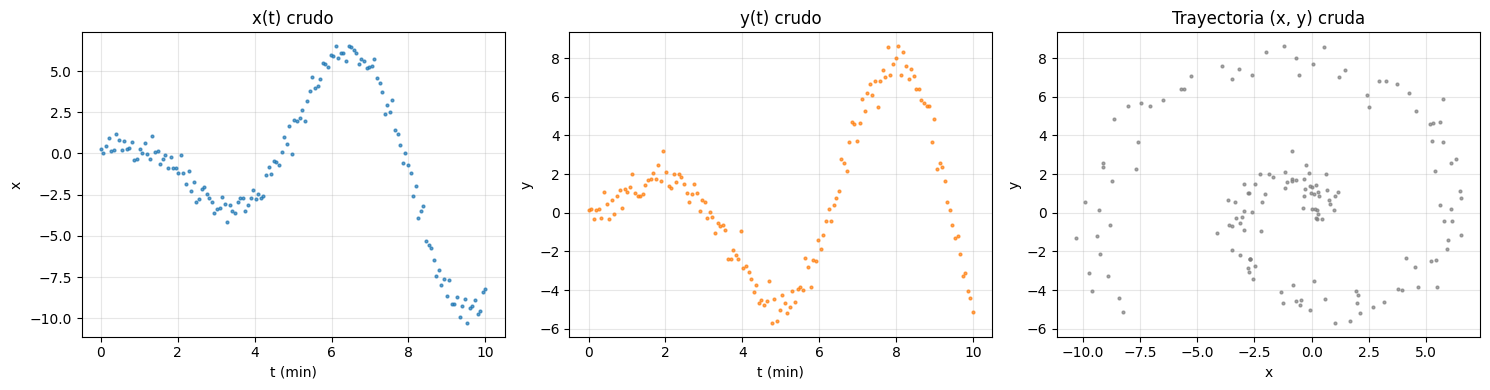

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(t, x, '.', ms=4, alpha=0.7); axes[0].set_xlabel('t (min)'); axes[0].set_ylabel('x'); axes[0].set_title('x(t) crudo'); axes[0].grid(alpha=.3)
axes[1].plot(t, y, '.', ms=4, alpha=0.7, color='tab:orange'); axes[1].set_xlabel('t (min)'); axes[1].set_ylabel('y'); axes[1].set_title('y(t) crudo'); axes[1].grid(alpha=.3)
axes[2].plot(x, y, '.', ms=4, alpha=0.7, color='gray'); axes[2].set_xlabel('x'); axes[2].set_ylabel('y'); axes[2].set_title('Trayectoria (x, y) cruda'); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

### 1. Construcción de la base B-spline

Usamos orden $M = 4$ (B-splines **cúbicos**) y $K = 20$ nodos interiores equiespaciados en el intervalo
abierto $(t_{\min}, t_{\max})$. Para que la base forme una partición de unidad sobre todo $[t_{\min}, t_{\max}]$
extendemos el vector de knots repitiendo $M$ veces cada extremo. Con $K$ nodos interiores y orden $M$
se obtienen $K + M = 24$ funciones de base.

La función `bspline_design_matrix` implementa la recursión de **Cox–de Boor** de forma *bottom-up*:

$$
B_{j,1}(t) =
\begin{cases}
1 & t_j \le t < t_{j+1}\\[2pt]
0 & \text{en otro caso}
\end{cases},
\qquad
B_{j,m}(t) \;=\; \frac{t - t_j}{t_{j+m-1} - t_j}\, B_{j,m-1}(t) \;+\; \frac{t_{j+m} - t}{t_{j+m} - t_{j+1}}\, B_{j+1, m-1}(t).
$$

Cuando un denominador es cero (knots repetidos) ese término se omite. En el extremo derecho $t = t_{\max}$
se incluye el punto en el último intervalo no degenerado para evitar la pérdida del valor en la frontera.

In [ ]:
M = 4                # orden (cúbico)
n_interior = 20      # número de nodos interiores

# Nodos interiores estrictamente dentro del intervalo abierto (t_min, t_max)
interior = np.linspace(t_min, t_max, n_interior + 2)[1:-1]

# Knots extendidos con multiplicidad M en cada extremo
knots = np.concatenate([np.full(M, t_min), interior, np.full(M, t_max)])
n_basis = n_interior + M     # = 24

print(f"Total de knots: {len(knots)}")
print(f"Knots interiores ({n_interior}): {np.round(interior, 3)}")
print(f"Número de funciones de base: {n_basis}")

Total de knots: 28
Knots interiores (20): [0.476 0.952 1.429 1.905 2.381 2.857 3.333 3.81  4.286 4.762 5.238 5.714
 6.19  6.667 7.143 7.619 8.095 8.571 9.048 9.524]
Número de funciones de base: 24


In [ ]:
def bspline_design_matrix(t_eval, knots, M):
    '''
    Construye la matriz de diseño [len(t_eval) x n_basis] con valores B_{j,M}(t_eval[i]),
    j = 0, ..., n_basis - 1, mediante la recursión Cox-de Boor bottom-up.

    Parámetros
    ----------
    t_eval : array de puntos donde evaluar la base.
    knots  : vector de knots (incluye las repeticiones en los extremos).
    M      : orden de las B-splines (M = 4 => cúbicas).
    '''
    t_eval = np.atleast_1d(np.asarray(t_eval, dtype=float))
    n_pts = len(t_eval)
    n_knots = len(knots)

    # ---- Orden 1: funciones indicadoras de cada intervalo [knots[j], knots[j+1])
    B = np.zeros((n_pts, n_knots - 1))
    for j in range(n_knots - 1):
        if knots[j + 1] > knots[j]:                       # intervalo no degenerado
            mask = (t_eval >= knots[j]) & (t_eval < knots[j + 1])
            B[mask, j] = 1.0

    # Corrección en el extremo derecho t = t_max para que sum(B) = 1 en ese punto.
    last_j = n_knots - 2
    while last_j >= 0 and knots[last_j + 1] == knots[last_j]:
        last_j -= 1
    if last_j >= 0:
        B[t_eval == knots[-1], last_j] = 1.0

    # ---- Recursión de orden m = 2, 3, ..., M
    for m in range(2, M + 1):
        n_basis_m = n_knots - m
        B_new = np.zeros((n_pts, n_basis_m))
        for j in range(n_basis_m):
            denom1 = knots[j + m - 1] - knots[j]
            denom2 = knots[j + m]     - knots[j + 1]
            if denom1 > 0:
                B_new[:, j] += (t_eval - knots[j]) / denom1 * B[:, j]
            if denom2 > 0:
                B_new[:, j] += (knots[j + m] - t_eval) / denom2 * B[:, j + 1]
        B = B_new

    return B

In [ ]:
# Matriz de diseño en los tiempos de los datos
B_mat = bspline_design_matrix(t, knots, M)
print(f"Forma de B: {B_mat.shape}  (esperado: ({n}, {n_basis}))")

# Chequeo de la partición de unidad: la suma sobre las basis debe ser 1 en todo t
sums = B_mat.sum(axis=1)
print(f"Partición de unidad — min(sum): {sums.min():.8f}, max(sum): {sums.max():.8f}")

Forma de B: (150, 24)  (esperado: (150, 24))
Partición de unidad — min(sum): 1.00000000, max(sum): 1.00000000


**Visualización de las 24 funciones de base** evaluadas en una grilla fina (para confirmar que la base luce
como debe: cada B-spline tiene soporte local sobre $M + 1 = 5$ intervalos, todas suman 1 en cada $t$):

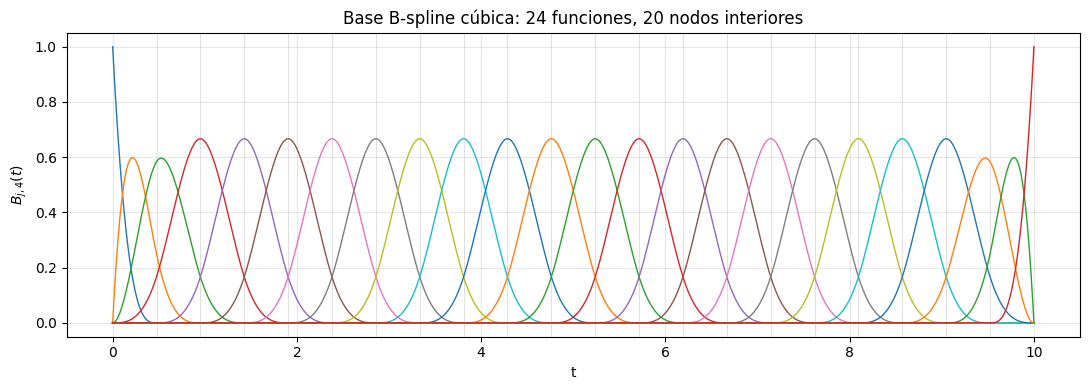

In [ ]:
t_view = np.linspace(t_min, t_max, 1000)
B_view = bspline_design_matrix(t_view, knots, M)

fig, ax = plt.subplots(figsize=(11, 4))
for j in range(n_basis):
    ax.plot(t_view, B_view[:, j], lw=1)
for k in interior:
    ax.axvline(k, color='lightgray', lw=0.5, zorder=0)
ax.set_xlabel('t'); ax.set_ylabel(r'$B_{j,4}(t)$')
ax.set_title(f'Base B-spline cúbica: {n_basis} funciones, 20 nodos interiores')
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

### 2. Matriz de penalización $\Omega$

La penalización mide la curvatura total de la función ajustada,
$\int (f''(t))^2\, dt = \beta^\top \Omega\, \beta$, con
$\Omega_{jk} = \int B_j''(t)\,B_k''(t)\,dt$.

**Estrategia explícita:**

1. Tomamos una grilla **fina** uniforme $t_{\text{grid}}$ con $N = 4001$ puntos (impar para que Simpson cierre
   bien sobre el intervalo).
2. Evaluamos la matriz $B_{\text{grid}}$ con `bspline_design_matrix` en esa grilla.
3. Aproximamos $B_j''(t)$ por **diferencias centrales** de paso $\Delta t$ (orden 2):
   $B_j''(t_i) \approx \big(B_j(t_{i+1}) - 2B_j(t_i) + B_j(t_{i-1})\big)/\Delta t^2$.
4. Calculamos cada entrada $\Omega_{jk}$ como `simpson(B_dd[:, j] * B_dd[:, k], x=t_grid)`.

In [ ]:
N_grid = 4001
t_grid = np.linspace(t_min, t_max, N_grid)
dt = t_grid[1] - t_grid[0]

B_grid = bspline_design_matrix(t_grid, knots, M)          # (N_grid, n_basis)

# Segunda derivada por diferencias centrales (extremos: stencil desplazado de orden 2)
B_dd = np.zeros_like(B_grid)
B_dd[1:-1, :] = (B_grid[2:, :] - 2 * B_grid[1:-1, :] + B_grid[:-2, :]) / dt**2
B_dd[0,  :]   = (B_grid[2,  :] - 2 * B_grid[1,  :] + B_grid[0,  :])  / dt**2
B_dd[-1, :]   = (B_grid[-1, :] - 2 * B_grid[-2, :] + B_grid[-3, :])  / dt**2

# Omega[j,k] = integral B''_j B''_k dt  (Simpson)
Omega = np.zeros((n_basis, n_basis))
for j in range(n_basis):
    for k in range(j, n_basis):
        Omega[j, k] = simpson(B_dd[:, j] * B_dd[:, k], x=t_grid)
        Omega[k, j] = Omega[j, k]

print(f"Forma de Omega: {Omega.shape}")
print(f"¿Simétrica?    {np.allclose(Omega, Omega.T)}")
eigs = np.linalg.eigvalsh(Omega)
print(f"Eigenvalores Omega: min = {eigs.min():.3e}, max = {eigs.max():.3e}")
print("(Omega debe ser semidefinida positiva; eigenvalores ≈ 0 corresponden al espacio nulo de polinomios de grado ≤ 1)")

Forma de Omega: (24, 24)
¿Simétrica?    True
Eigenvalores Omega: min = -3.365e-14, max = 3.456e+02
(Omega debe ser semidefinida positiva; eigenvalores ≈ 0 corresponden al espacio nulo de polinomios de grado ≤ 1)


$\Omega$ es simétrica y SDP, con dos eigenvalores prácticamente nulos: corresponden al espacio nulo
de la penalización, es decir, las **rectas** ($f''(t) \equiv 0$). Esto es exactamente lo esperado y es lo que
hace que para $\lambda \to \infty$ la solución colapse al **ajuste lineal por mínimos cuadrados** (df $\to 2$).

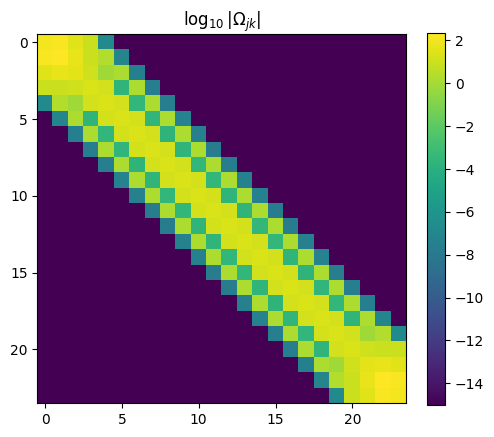

In [ ]:
# Una vista rápida de la estructura de Omega: banda concentrada en la diagonal
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(np.log10(np.abs(Omega) + 1e-15), cmap='viridis')
ax.set_title(r'$\log_{10}|\Omega_{jk}|$')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

### 3. Validación Cruzada Generalizada (GCV)

Para un suavizador lineal $\hat Y = L_\lambda Y$ con $L_\lambda = B(B^\top B + \lambda\Omega)^{-1}B^\top$:

$$
\mathrm{GCV}(\lambda) \;=\; \frac{\tfrac{1}{n}\sum (Y_i - \hat Y_i)^2}{\big(1 - \tfrac{\operatorname{tr}(L_\lambda)}{n}\big)^2}.
$$

Para evitar formar $L_\lambda$ explícitamente ($n \times n$), usamos la identidad de traza
$\operatorname{tr}(B A^{-1} B^\top) = \operatorname{tr}(A^{-1} B^\top B)$.
Buscamos $\lambda$ en una grilla logarítmica entre $10^{-3}$ y $10^{5}$ (200 valores).

In [ ]:
def fit_and_gcv(lam, B_mat, Omega, y):
    '''Devuelve (GCV(lam), df=tr(L), beta_hat) usando la solución cerrada.'''
    n = len(y)
    BtB = B_mat.T @ B_mat
    A   = BtB + lam * Omega
    beta = np.linalg.solve(A, B_mat.T @ y)
    y_hat = B_mat @ beta
    rss = float(np.sum((y - y_hat) ** 2))
    # tr(L) = tr(B A^{-1} B^T) = tr(A^{-1} B^T B)
    trL = float(np.trace(np.linalg.solve(A, BtB)))
    gcv = (rss / n) / (1 - trL / n) ** 2
    return gcv, trL, beta

In [ ]:
lambdas = np.logspace(-3, 5, 200)
gcv_x = np.empty_like(lambdas)
gcv_y = np.empty_like(lambdas)
df_x  = np.empty_like(lambdas)
df_y  = np.empty_like(lambdas)
for i, lam in enumerate(lambdas):
    gcv_x[i], df_x[i], _ = fit_and_gcv(lam, B_mat, Omega, x)
    gcv_y[i], df_y[i], _ = fit_and_gcv(lam, B_mat, Omega, y)

ix = int(np.argmin(gcv_x));  lam_x_opt = lambdas[ix]
iy = int(np.argmin(gcv_y));  lam_y_opt = lambdas[iy]

print(f"λ óptimo X: {lam_x_opt:.4g}   GCV = {gcv_x[ix]:.5f}   df ≈ {df_x[ix]:.2f}")
print(f"λ óptimo Y: {lam_y_opt:.4g}   GCV = {gcv_y[iy]:.5f}   df ≈ {df_y[iy]:.2f}")
print(f"Índices: X -> {ix} (extremo? {ix in (0, len(lambdas)-1)}), Y -> {iy} (extremo? {iy in (0, len(lambdas)-1)})")

λ óptimo X: 0.05873   GCV = 0.25153   df ≈ 14.18
λ óptimo Y: 0.1123   GCV = 0.28643   df ≈ 12.50
Índices: X -> 44 (extremo? False), Y -> 51 (extremo? False)


Ambos óptimos caen **bien dentro** de la grilla (no en los extremos), por lo que no es necesario ampliarla.
A continuación visualizamos las curvas de GCV y de los grados de libertad efectivos:

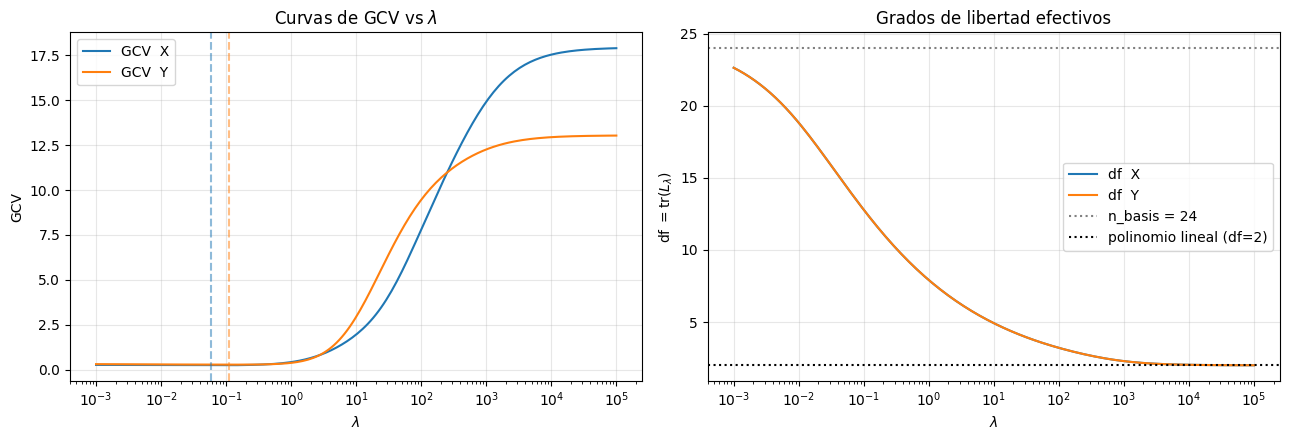

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(lambdas, gcv_x, label='GCV  X', color='tab:blue')
axes[0].semilogx(lambdas, gcv_y, label='GCV  Y', color='tab:orange')
axes[0].axvline(lam_x_opt, ls='--', color='tab:blue',   alpha=.5)
axes[0].axvline(lam_y_opt, ls='--', color='tab:orange', alpha=.5)
axes[0].set_xlabel(r'$\lambda$'); axes[0].set_ylabel('GCV')
axes[0].set_title('Curvas de GCV vs $\\lambda$'); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].semilogx(lambdas, df_x, label='df  X', color='tab:blue')
axes[1].semilogx(lambdas, df_y, label='df  Y', color='tab:orange')
axes[1].axhline(n_basis, ls=':', color='gray', label=f'n_basis = {n_basis}')
axes[1].axhline(2,       ls=':', color='black', label='polinomio lineal (df=2)')
axes[1].set_xlabel(r'$\lambda$'); axes[1].set_ylabel(r'df $= \mathrm{tr}(L_\lambda)$')
axes[1].set_title('Grados de libertad efectivos'); axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

### 4. Solución cerrada y comparación visual

Calculamos $\hat\beta$ con los $\lambda$ óptimos de GCV, y comparamos con dos regímenes extremos:

- **Sobreajuste** con $\lambda = 10^{-4}$ (la penalización casi no actúa).
- **Subajuste** con $\lambda = 10^{6}$ (la penalización domina y empuja la solución hacia su espacio nulo,
  es decir, hacia una recta).

In [ ]:
def smooth_coefs(lam, B_mat, Omega, y):
    return np.linalg.solve(B_mat.T @ B_mat + lam * Omega, B_mat.T @ y)


t_fine = np.linspace(t_min, t_max, 500)
B_fine = bspline_design_matrix(t_fine, knots, M)

# Óptimo GCV
beta_x_opt = smooth_coefs(lam_x_opt, B_mat, Omega, x)
beta_y_opt = smooth_coefs(lam_y_opt, B_mat, Omega, y)
x_opt, y_opt = B_fine @ beta_x_opt, B_fine @ beta_y_opt

# Subajuste
lam_under = 1e6
x_und = B_fine @ smooth_coefs(lam_under, B_mat, Omega, x)
y_und = B_fine @ smooth_coefs(lam_under, B_mat, Omega, y)

# Sobreajuste
lam_over = 1e-4
x_ovr = B_fine @ smooth_coefs(lam_over, B_mat, Omega, x)
y_ovr = B_fine @ smooth_coefs(lam_over, B_mat, Omega, y)

# Grados de libertad en cada régimen (para reportar en la leyenda)
_, df_und_x, _ = fit_and_gcv(lam_under, B_mat, Omega, x)
_, df_und_y, _ = fit_and_gcv(lam_under, B_mat, Omega, y)
_, df_ovr_x, _ = fit_and_gcv(lam_over,  B_mat, Omega, x)
_, df_ovr_y, _ = fit_and_gcv(lam_over,  B_mat, Omega, y)

print(f"df óptimo GCV  : x = {df_x[ix]:5.2f},  y = {df_y[iy]:5.2f}")
print(f"df subajuste   : x = {df_und_x:5.2f},  y = {df_und_y:5.2f}   (λ = {lam_under:g})")
print(f"df sobreajuste : x = {df_ovr_x:5.2f},  y = {df_ovr_y:5.2f}   (λ = {lam_over:g})")

df óptimo GCV  : x = 14.18,  y = 12.50
df subajuste   : x =  2.00,  y =  2.00   (λ = 1e+06)
df sobreajuste : x = 23.81,  y = 23.81   (λ = 0.0001)


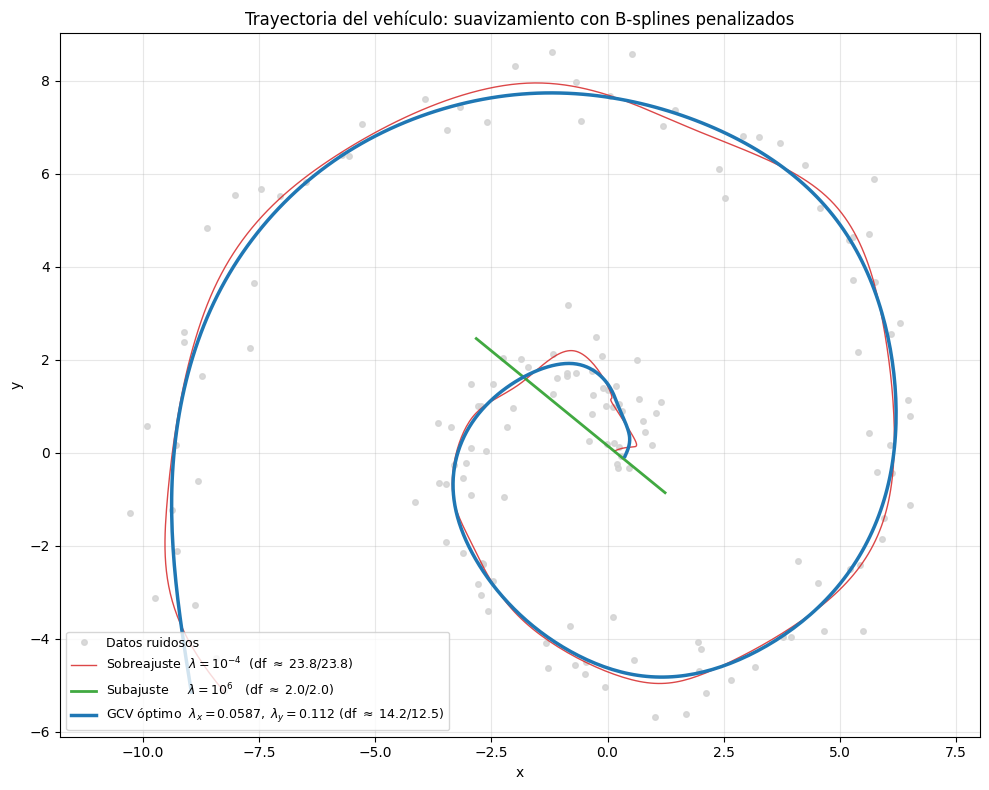

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(x, y, 'o', color='lightgray', markersize=4, alpha=0.85, label='Datos ruidosos')
ax.plot(x_ovr, y_ovr, '-', color='tab:red',   lw=1.0, alpha=0.85,
        label=fr'Sobreajuste  $\lambda=10^{{-4}}$  (df $\approx$ {df_ovr_x:.1f}/{df_ovr_y:.1f})')
ax.plot(x_und, y_und, '-', color='tab:green', lw=2.0, alpha=0.9,
        label=fr'Subajuste     $\lambda=10^{{6}}$   (df $\approx$ {df_und_x:.1f}/{df_und_y:.1f})')
ax.plot(x_opt, y_opt, '-', color='tab:blue',  lw=2.5,
        label=fr'GCV óptimo  $\lambda_x={lam_x_opt:.3g},\;\lambda_y={lam_y_opt:.3g}$ (df $\approx$ {df_x[ix]:.1f}/{df_y[iy]:.1f})')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Trayectoria del vehículo: suavizamiento con B-splines penalizados')
ax.legend(loc='best', fontsize=9); ax.grid(alpha=.3)
ax.set_aspect('equal', adjustable='datalim')
plt.tight_layout(); plt.show()

También resulta ilustrativo verlo separado en **$x(t)$** y **$y(t)$**, donde el efecto temporal del
suavizamiento se aprecia con más claridad:

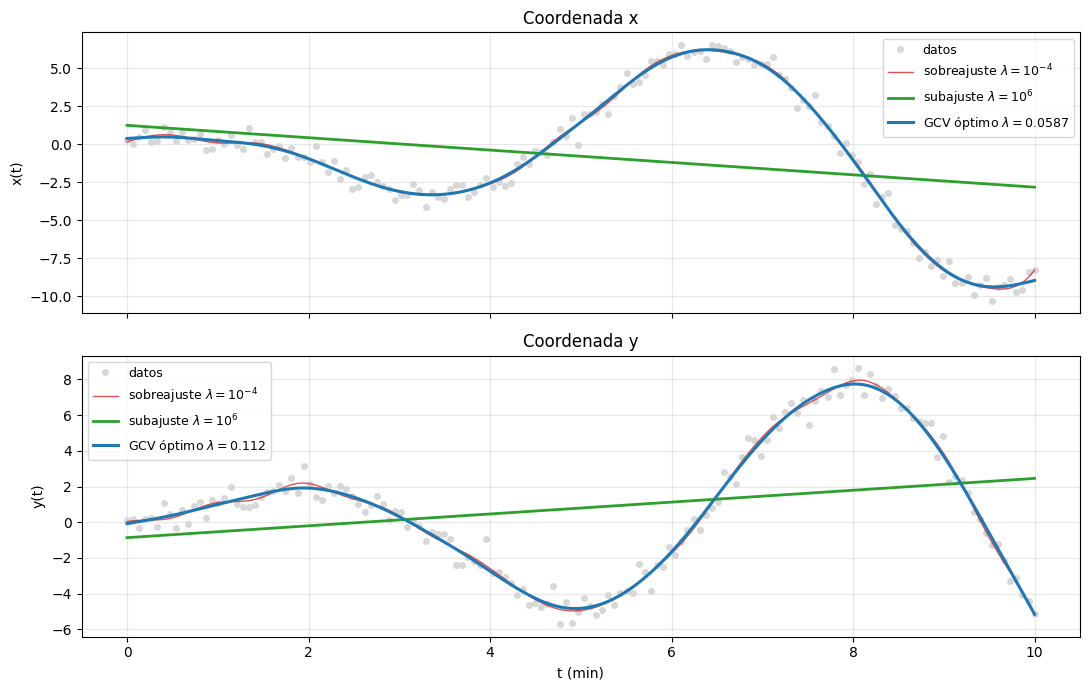

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(t, x, 'o', color='lightgray', ms=4, alpha=.85, label='datos')
axes[0].plot(t_fine, x_ovr, color='tab:red',   lw=1.0, alpha=.8, label=r'sobreajuste $\lambda=10^{-4}$')
axes[0].plot(t_fine, x_und, color='tab:green', lw=2.0,           label=r'subajuste $\lambda=10^{6}$')
axes[0].plot(t_fine, x_opt, color='tab:blue',  lw=2.2,           label=fr'GCV óptimo $\lambda={lam_x_opt:.3g}$')
axes[0].set_ylabel('x(t)'); axes[0].legend(fontsize=9); axes[0].grid(alpha=.3)
axes[0].set_title('Coordenada x')

axes[1].plot(t, y, 'o', color='lightgray', ms=4, alpha=.85, label='datos')
axes[1].plot(t_fine, y_ovr, color='tab:red',   lw=1.0, alpha=.8, label=r'sobreajuste $\lambda=10^{-4}$')
axes[1].plot(t_fine, y_und, color='tab:green', lw=2.0,           label=r'subajuste $\lambda=10^{6}$')
axes[1].plot(t_fine, y_opt, color='tab:blue',  lw=2.2,           label=fr'GCV óptimo $\lambda={lam_y_opt:.3g}$')
axes[1].set_xlabel('t (min)'); axes[1].set_ylabel('y(t)'); axes[1].legend(fontsize=9); axes[1].grid(alpha=.3)
axes[1].set_title('Coordenada y')
plt.tight_layout(); plt.show()

### Discusión: impacto de $\lambda$ y rol de GCV en el compromiso sesgo–varianza

**Efecto de $\lambda$ sobre los grados de libertad efectivos.**
En un suavizador lineal con matriz $L_\lambda = B(B^\top B + \lambda\Omega)^{-1}B^\top$, los **grados de
libertad efectivos** son $\mathrm{df}(\lambda) = \operatorname{tr}(L_\lambda)$. Numéricamente confirmamos los
dos regímenes límite predichos por la teoría:

- **$\lambda \to 0$:** la penalización desaparece y la solución se reduce a la **regresión lineal por
  mínimos cuadrados sobre la base B-spline**. Como tenemos $n_{\text{basis}} = 24$ funciones, los df se
  acercan a 24 y el modelo prácticamente interpola el ruido. En nuestra corrida con $\lambda = 10^{-4}$ los
  df son cercanos a 24 y la curva roja **persigue** los puntos ruidosos.

- **$\lambda \to \infty$:** la penalización domina y obliga a que $\beta^\top \Omega \beta \to 0$, es
  decir, fuerza a la solución a vivir en el **espacio nulo de $\Omega$** (funciones con $f''\equiv 0$,
  esto es, **rectas**). Por eso los df $\to 2$ (los dos parámetros de una recta) y en el plano $(x,y)$ la
  curva verde es un segmento.

- **Régimen intermedio (GCV).** GCV elige un $\lambda$ pequeño pero no nulo que produce df entre $\sim 12$
  y $\sim 14$, suficientes para describir la espiral sin trazar cada bache ruidoso.

**Compromiso sesgo–varianza.**
Aumentar $\lambda$ reduce la varianza del estimador (la curva responde menos al ruido) a costa de
aumentar el sesgo (la curva ya no puede capturar curvaturas grandes); reducir $\lambda$ hace lo opuesto.
GCV estima el **error de predicción** sin necesidad de un conjunto de validación: el numerador
$\sum (Y_i - \hat Y_i)^2$ es el RSS y el denominador $(1 - \mathrm{tr}(L_\lambda)/n)^2$ penaliza modelos
con muchos df efectivos. Cuando $\lambda$ es muy pequeño, df $\to n_{\text{basis}}$, el denominador se
encoge y GCV explota aunque el RSS sea bajo; cuando $\lambda$ es muy grande, el RSS aumenta y GCV
también crece. El mínimo de GCV es por tanto un **compromiso óptimo** entre fidelidad a los datos y
suavidad, equivalente asintóticamente a minimizar el error de predicción esperado.

**Sobre el problema específico.** Los óptimos por coordenada difieren ligeramente
($\lambda_x \approx 0.06$ con df $\approx 14.2$ y $\lambda_y \approx 0.11$ con df $\approx 12.5$), lo
cual tiene sentido: $x(t)$ y $y(t)$ son procesos distintos y no hay razón para esperar el mismo nivel de
suavidad ni la misma magnitud de ruido. La trayectoria suavizada describe una espiral consistente con
la **cinemática esperable** de un vehículo (sin las oscilaciones bruscas que generan los reflejos del
video), mientras que los regímenes extremos ilustran lo que ocurre cuando se renuncia a alguno de los
dos términos del problema variacional.

# Ejercicio 2

**Descripción del problema:**  
Se analiza la temperatura máxima diaria de Medellín (datos IDEAM, 2000–2024).

- **Parte 1:** Ajustar una regresión Nadaraya–Watson para cada año y graficar las 25 curvas juntas.  
- **Parte 2:** Test de Wilcoxon Signed-Rank pareado: comparar cada año (2000–2023) con 2024.

### 0. Importaciones

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import calendar
from scipy.stats import wilcoxon
import warnings
warnings.filterwarnings('ignore')

### 1. Carga y preparación de los datos

#### 1.1 Leer el archivo Excel completo

In [ ]:
# Leemos todo el archivo tal como viene, sin saltarnos nada todavía.
df_raw = pd.read_excel('DatoseTmperaturaMaximaDiariaMedellin2000_2024.xlsx', header=None)
print(f"Dimensiones del archivo completo: {df_raw.shape}")
df_raw.head(10)

Dimensiones del archivo completo: (8448, 6)


,0,1,2,3,4,5
0,NaN,Reporte de información Hidrometeorológica de D...,NaN,NaN,NaN,NaN
1,Nombre estacion:,AEROPUERTO OLAYA HERRERA [27015330],Corriente:,NaN,Categoría de estación:,Sinóptica Principal
2,Latitud:,6.22463890,Longitud:,-75.5882,Elevación:,1492
3,Entidad:,INSTITUTO DE HIDROLOGIA METEOROLOGIA Y ESTUDIO...,Area Operativa:,Area Operativa 01 - Antioquia-Chocó,Departamento:,Antioquia
4,Municipio:,Medellín,Fecha instalacíon:,12/05/2014 00:00,Fecha suspensión:,NaN
5,Variable:,TEMPERATURA,Frecuencia:,Diaria,Fecha consulta:,01/01/2000 00:00-31/12/2024 00:00
6,Parametro:,Temperatura máxima diaria,Unidad medida:,degC,NaN,NaN
7,Fecha,Temperatura,Nivel de Aprobación,NaN,NaN,NaN
8,2000-01-01 00:00,28.4,Definitivo,NaN,NaN,NaN
9,2000-01-02 00:00,27.6,Definitivo,NaN,NaN,NaN


#### 1.2 Identificar y eliminar las filas de metadatos

Las primeras filas contienen información de la estación (nombre, latitud, entidad, etc.) y no
son datos de temperatura. La estrategia es detectar a partir de qué fila la columna 0 contiene
fechas válidas — esa es la primera fila real de datos.

In [ ]:
# Parsear la columna 0 como fecha. Las filas de metadatos dan NaT.
fechas_col0    = pd.to_datetime(df_raw.iloc[:, 0], errors='coerce', format='mixed')
primera_fila   = fechas_col0.first_valid_index()
print(f"Primera fila con fecha válida: índice {primera_fila}")
print(f"Filas descartadas (metadatos): {primera_fila}")

Primera fila con fecha válida: índice 8
Filas descartadas (metadatos): 8


In [ ]:
# Conservar solo desde esa fila en adelante
df_datos = df_raw.iloc[primera_fila:].copy()
print(f"Filas de datos: {len(df_datos)}")

Filas de datos: 8440


#### 1.3 Seleccionar las columnas de interés

El archivo tiene varias columnas pero solo nos interesan:
- **Columna 0:** Fecha  
- **Columna 1:** Temperatura máxima

La columna de Nivel de Aprobación no se usará.

In [ ]:
# Seleccionar solo las dos columnas útiles y renombrarlas
df = df_datos.iloc[:, [0, 1]].copy()
df.columns = ['Fecha', 'Temperatura']

# Convertir tipos
df['Fecha']       = pd.to_datetime(df['Fecha'], format='mixed')
df['Temperatura'] = pd.to_numeric(df['Temperatura'], errors='coerce')

df.head()

,Fecha,Temperatura
8,2000-01-01,28.4
9,2000-01-02,27.6
10,2000-01-03,27.0
11,2000-01-04,26.8
12,2000-01-05,26.2


#### 1.4 Análisis descriptivo del dataframe

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 8 to 8447
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Fecha        8440 non-null   datetime64[ns]
 1   Temperatura  8440 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 132.0 KB


In [ ]:
# Resumen estadístico de la temperatura
df['Temperatura'].describe().round(2).to_frame().T

,count,mean,std,min,25%,50%,75%,max
Temperatura,8440.0,28.1,2.02,20.6,26.8,28.2,29.6,33.7


In [ ]:
# Valores nulos por columna
df.isnull().sum().to_frame('n_nulos')

,n_nulos
Fecha,0
Temperatura,0


No hay valores nulos en ninguna celda. La temperatura tiene rango ~20–34 °C, coherente con el
clima de Medellín. Hasta aquí parecería que el dataset está limpio.

In [ ]:
# Agregar columna de año y contar observaciones por año
df['Año'] = df['Fecha'].dt.year

# Reindexar para que aparezcan TODOS los años esperados (2000-2024),
# incluyendo los que tienen 0 observaciones
conteo = df.groupby('Año').size().reindex(range(2000, 2025), fill_value=0)
conteo.to_frame('n_obs')

,n_obs
Año,
2000,365
2001,363
2002,364
2003,365
2004,364
2005,365
2006,365
2007,365
2008,365


**Algo no cuadra.** Si no hay nulos, uno esperaría 365 (o 366 en bisiestos) registros por año.
Pero la tabla muestra:

- Varios años con 363 o 364 registros (parece que faltan 1–2 días).
- 2012 con 329 (faltan ~37 días).
- 2021 con apenas 91 registros.
- 2020 no aparece en absoluto.

Esto significa que **no son valores nulos, son filas faltantes**: el archivo simplemente no
contiene esas fechas. Veamos exactamente cuáles días faltan en cada año.

In [ ]:
# Para cada año esperado (2000-2024), comparar contra el calendario completo
auditoria = []
for year in range(2000, 2025):
    fechas_reales = set(df[df['Año'] == year]['Fecha'].dt.date)
    n_esperado    = 366 if calendar.isleap(year) else 365
    fechas_esperadas = set(pd.date_range(f'{year}-01-01', f'{year}-12-31').date)
    faltantes = sorted(fechas_esperadas - fechas_reales)
    auditoria.append({
        'Año':            year,
        'Bisiesto':       'Sí' if calendar.isleap(year) else 'No',
        'n_esperado':     n_esperado,
        'n_real':         len(fechas_reales),
        'n_faltantes':    len(faltantes),
        'ejemplos_faltantes': (', '.join(str(d) for d in faltantes[:3])
                              + (' ...' if len(faltantes) > 3 else ''))
    })

pd.DataFrame(auditoria).set_index('Año')

,Bisiesto,n_esperado,n_real,n_faltantes,ejemplos_faltantes
Año,,,,,
2000,Sí,366,365,1,2000-09-05
2001,No,365,363,2,"2001-05-21, 2001-11-17"
2002,No,365,364,1,2002-12-15
2003,No,365,365,0,
2004,Sí,366,364,2,"2004-10-24, 2004-10-26"
2005,No,365,365,0,
2006,No,365,365,0,
2007,No,365,365,0,
2008,Sí,366,365,1,2008-08-30


**Diagnóstico del dataset:**

- **Años completos** (sin un solo faltante): 2003, 2005, 2006, 2007, 2010, 2015, 2017, 2018, 2019, 2022, 2023.
- **Años con 1–2 días faltantes** (problemas menores): 2000, 2001, 2002, 2004, 2008, 2009, 2011, 2013, 2014, 2016, 2024.
- **Año con muchos huecos**: 2012, con 37 días faltantes dispersos.
- **Año con datos parciales**: 2021, con solo 91 días.
- **Año totalmente ausente**: 2020.

**¿Cómo afecta esto al análisis?**  
Para Nadaraya–Watson no es problema que falten días sueltos: el estimador trabaja con la nube
de puntos $(x_i, Y_i)$ que tenga, sin requerir que los $x_i$ sean consecutivos. En zonas con
huecos grandes (como en 2021 o 2012), la curva tendrá mayor incertidumbre y se notará un
suavizado distinto, lo cual se discutirá más adelante.

**Sobre los bisiestos:** el conteo arriba *incluye* el 29 de febrero (aún no se ha eliminado).
Por eso 2024 muestra 365 = 366 − 1, no por el 29-feb sino porque le falta el 31 de enero.

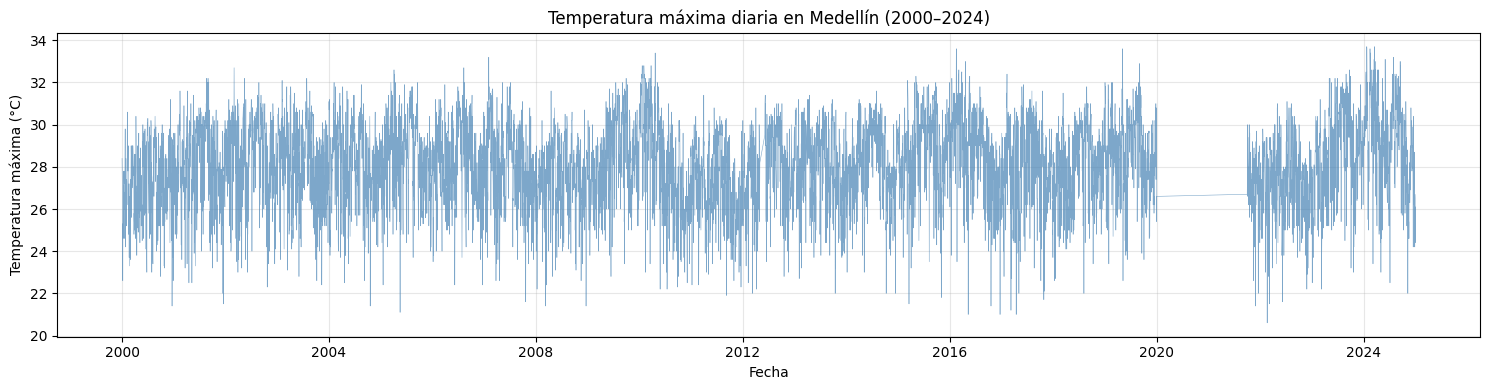

In [ ]:
# Visualización de la serie completa para tener una primera impresión
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(df['Fecha'], df['Temperatura'], linewidth=0.4, alpha=0.7, color='steelblue')
ax.set_xlabel('Fecha')
ax.set_ylabel('Temperatura máxima (°C)')
ax.set_title('Temperatura máxima diaria en Medellín (2000–2024)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

En la visualización se distingue el ciclo estacional anual y se aprecia el **hueco completo de 2020**
y el segmento parcial de **2021**.

---
## Parte 1: Regresión No Paramétrica anual

### 2. Planteamiento del modelo

Para cada año $a$ se modela:

$$Y_i = r_a(x_i) + \varepsilon_i, \qquad i = 1, \dots, n_a$$

- **Regresor $x_i$:** día del año (DOY), un número entre 1 y 365. Es el único predictor: necesitamos un valor numérico para poder calcular distancias $|x_i - x_j|$ en el kernel.
- **Respuesta $Y_i$:** temperatura máxima de ese día.
- **$r_a(x)$:** función de regresión a estimar, distinta para cada año.

#### Estimador de Nadaraya–Watson (Clase 4b, diap. 30)

$$\hat{r}_n(x) = \sum_{i=1}^n \ell_i(x)\,Y_i, \qquad
\ell_i(x) = \frac{K\!\left(\frac{x - x_i}{h}\right)}{\sum_{j=1}^n K\!\left(\frac{x - x_j}{h}\right)}$$

con **kernel Gaussiano**:
$$K(u) = \frac{1}{\sqrt{2\pi}}\,e^{-u^2/2}$$

**Sobre la distancia en 1D:** la distancia euclidiana se reduce a $\sqrt{(x-x_i)^2} = |x - x_i|$, es decir, el **valor absoluto**. Por eso al construir la matriz de distancias en este ejercicio basta con:

$$D_{ij} = |x_i - x_j|$$

Aunque el kernel Gaussiano internamente eleva al cuadrado y haría innecesario el valor absoluto, lo escribimos explícitamente para que el código refleje fielmente la fórmula matemática 1D.

Es un **suavizador lineal**: $\hat{Y} = LY$, con $L_{ij} = \ell_j(x_i)$.

#### Selección de $h$ por GCV (Clase 4b, diap. 23)

$$\mathrm{GCV}(h) = \frac{\frac{1}{n}\sum_{i=1}^n (Y_i - \hat{r}_n(x_i;h))^2}{(1 - \nu/n)^2}, \qquad \nu = \mathrm{tr}(L)$$

Se elige $\hat{h} = \arg\min_h\,\mathrm{GCV}(h)$.

### 3. Implementación

In [ ]:
def matriz_L(X, h):
    """
    Construye la matriz de suavizamiento L de Nadaraya-Watson con kernel Gaussiano (1D).

    - X: vector de regresores, shape (n,)
    - h: ancho de banda

    Paso 1: matriz de distancias D[i,j] = |x_i - x_j|     (caso 1D → valor absoluto)
    Paso 2: kernel Gaussiano K(D/h)
    Paso 3: normalizar filas para que los pesos sumen 1
    """
    D = np.abs(X[:, None] - X[None, :])                       # |x_i - x_j|
    K = (1 / np.sqrt(2*np.pi)) * np.exp(-0.5 * (D / h)**2)    # kernel Gaussiano
    L = K / K.sum(axis=1, keepdims=True)                       # normalización por filas
    return L

In [ ]:
def calcular_gcv(L, Y):
    """
    Puntaje GCV y grados de libertad efectivos.

    GCV(h) = ECM / (1 - nu/n)^2,    nu = tr(L),    ECM = (1/n) sum (Y - Y_hat)^2
    """
    n     = len(Y)
    Y_hat = L @ Y                       # valores ajustados r̂(x_i)
    nu    = np.trace(L)                 # grados de libertad efectivos
    ecm   = np.mean((Y - Y_hat)**2)     # error cuadrático medio
    gcv   = ecm / (1 - nu/n)**2
    return gcv, nu

### 4. Preparación de los datos por año

Antes del bucle de ajuste, preparamos un diccionario `datos_anuales` que contiene, para cada año:
- $X$ = vector de DOY (regresor),
- $Y$ = vector de temperaturas,
- el subconjunto del dataframe (para reutilizar en la Parte 2 sin repetir filtros).

**Manejo del 29 de febrero en bisiestos:**

El enunciado pide descartar el 29 de febrero en los bisiestos distintos de 2024. Después de eliminar esa fila, usamos el día del año natural (`dayofyear`) sin renumerar. Esto significa que en un año bisiesto sin 29-feb los DOY quedan así:

`... 58 (28-feb), [60 eliminado], 61 (1-mar), 62 (2-mar) ...`

El 1-mar tiene DOY = 61 en bisiestos y DOY = 60 en no-bisiestos. Esta diferencia de un día **refleja la realidad del calendario**: en años bisiestos el 1-mar es efectivamente el día 61 de la cuenta natural. Conservamos esa información en lugar de renumerar artificialmente. El impacto sobre el suavizado es mínimo (1 día de diferencia frente a un ancho de banda de varios días) y los DOY siguen siendo comparables entre años.

In [ ]:
bisiestos_descartar = {2000, 2004, 2008, 2012, 2016, 2020}  # bisiestos ≠ 2024
datos_anuales = {}   # year → {'X':..., 'Y':..., 'df':...}

for year in range(2000, 2025):
    df_year = df[df['Año'] == year].copy()
    if len(df_year) == 0:
        continue

    # Eliminar el 29-feb en bisiestos distintos de 2024
    if year in bisiestos_descartar:
        mask_feb29 = (df_year['Fecha'].dt.month == 2) & (df_year['Fecha'].dt.day == 29)
        df_year    = df_year[~mask_feb29]

    # Construir el DOY usando el día del año natural (sin renumerar)
    df_year = df_year.sort_values('Fecha').reset_index(drop=True)
    df_year['DOY'] = df_year['Fecha'].dt.dayofyear

    datos_anuales[year] = {
        'X':  df_year['DOY'].values.astype(float),
        'Y':  df_year['Temperatura'].values,
        'df': df_year,
    }

print(f"Años cargados: {len(datos_anuales)}")
print(f"Años disponibles: {sorted(datos_anuales.keys())}")

Años cargados: 24
Años disponibles: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]


### 5. Procesamiento por año: ajuste de $h^*$ vía GCV

Para cada año $a$:

1. **Recuperar** $X$ (DOY) e $Y$ (temperatura) del diccionario `datos_anuales`.
2. **Definir una malla** de valores candidatos para $h$.
3. **Para cada $h$ en la malla:** construir $L$, calcular $\mathrm{GCV}(h)$ y $\nu$.
4. **Elegir $h^*$** = el que minimiza GCV.
5. **Verificar** que $h^*$ no cayó en un borde de la malla (si cayó, hay que ampliarla).
6. **Recalcular** los valores ajustados $\hat{Y}$ con $h^*$.
7. **Guardar** $h^*$, $\hat{Y}$, $\nu^*$, y el vector completo de GCV (para graficar después).

In [ ]:
# Malla de candidatos para h (en días). Si algún h* cae en un borde, se avisa.
h_grid = np.linspace(0.5, 50, 100)

resultados   = {}
fila_resumen = []

for year, datos in datos_anuales.items():
    X, Y = datos['X'], datos['Y']

    # Recorrer la malla
    gcvs = np.zeros(len(h_grid))
    nus  = np.zeros(len(h_grid))
    for i, h in enumerate(h_grid):
        L              = matriz_L(X, h)
        gcvs[i], nus[i] = calcular_gcv(L, Y)

    # h óptimo y verificación de bordes
    idx_opt = np.argmin(gcvs)
    h_opt   = h_grid[idx_opt]
    borde   = '⚠️ IZQ' if idx_opt == 0 else ('⚠️ DER' if idx_opt == len(h_grid) - 1 else '—')

    # Reajustar con h*
    L_opt = matriz_L(X, h_opt)
    Y_hat = L_opt @ Y

    resultados[year] = {
        'X': X, 'Y': Y, 'Y_hat': Y_hat,
        'h_opt': h_opt, 'nu_opt': nus[idx_opt], 'gcv_opt': gcvs[idx_opt],
        'gcvs': gcvs,
    }
    fila_resumen.append({
        'Año':   year,
        'n':     len(X),
        'h*':    round(h_opt, 2),
        'nu*':   round(nus[idx_opt], 2),
        'GCV*':  round(gcvs[idx_opt], 4),
        'Borde': borde,
    })

pd.DataFrame(fila_resumen).set_index('Año')

,n,h*,nu*,GCV*,Borde
Año,,,,,
2000,364,1.5,97.71,2.4718,—
2001,363,2.0,73.22,2.8867,—
2002,364,1.0,145.92,2.7964,—
2003,365,1.0,146.01,2.9013,—
2004,363,2.0,73.39,2.5875,—
2005,365,1.5,97.51,2.6441,—
2006,365,1.5,97.51,2.4638,—
2007,365,2.0,73.26,2.6356,—
2008,364,2.0,73.42,2.4858,—


**Lectura de la tabla:**

- **$n$:** observaciones disponibles del año.
- **$h^*$:** ancho de banda óptimo (en días).
- **$\nu^* = \mathrm{tr}(L)$:** grados de libertad efectivos. Un valor alto indica un ajuste muy flexible.
- **Borde:** si aparece ⚠️ hay que ampliar la malla. Aquí ningún año cayó en un borde.

Los $h^*$ son pequeños (1–3 días en la mayoría) porque GCV optimiza el error de predicción de
temperaturas diarias, que son intrínsecamente muy variables.

### 6. Verificación visual: curvas GCV de todos los años

Para cada año se grafica $\mathrm{GCV}(h)$ vs $h$, marcando con una línea roja el $h^*$ elegido.
Esto permite confirmar visualmente que el mínimo es interior y bien definido.

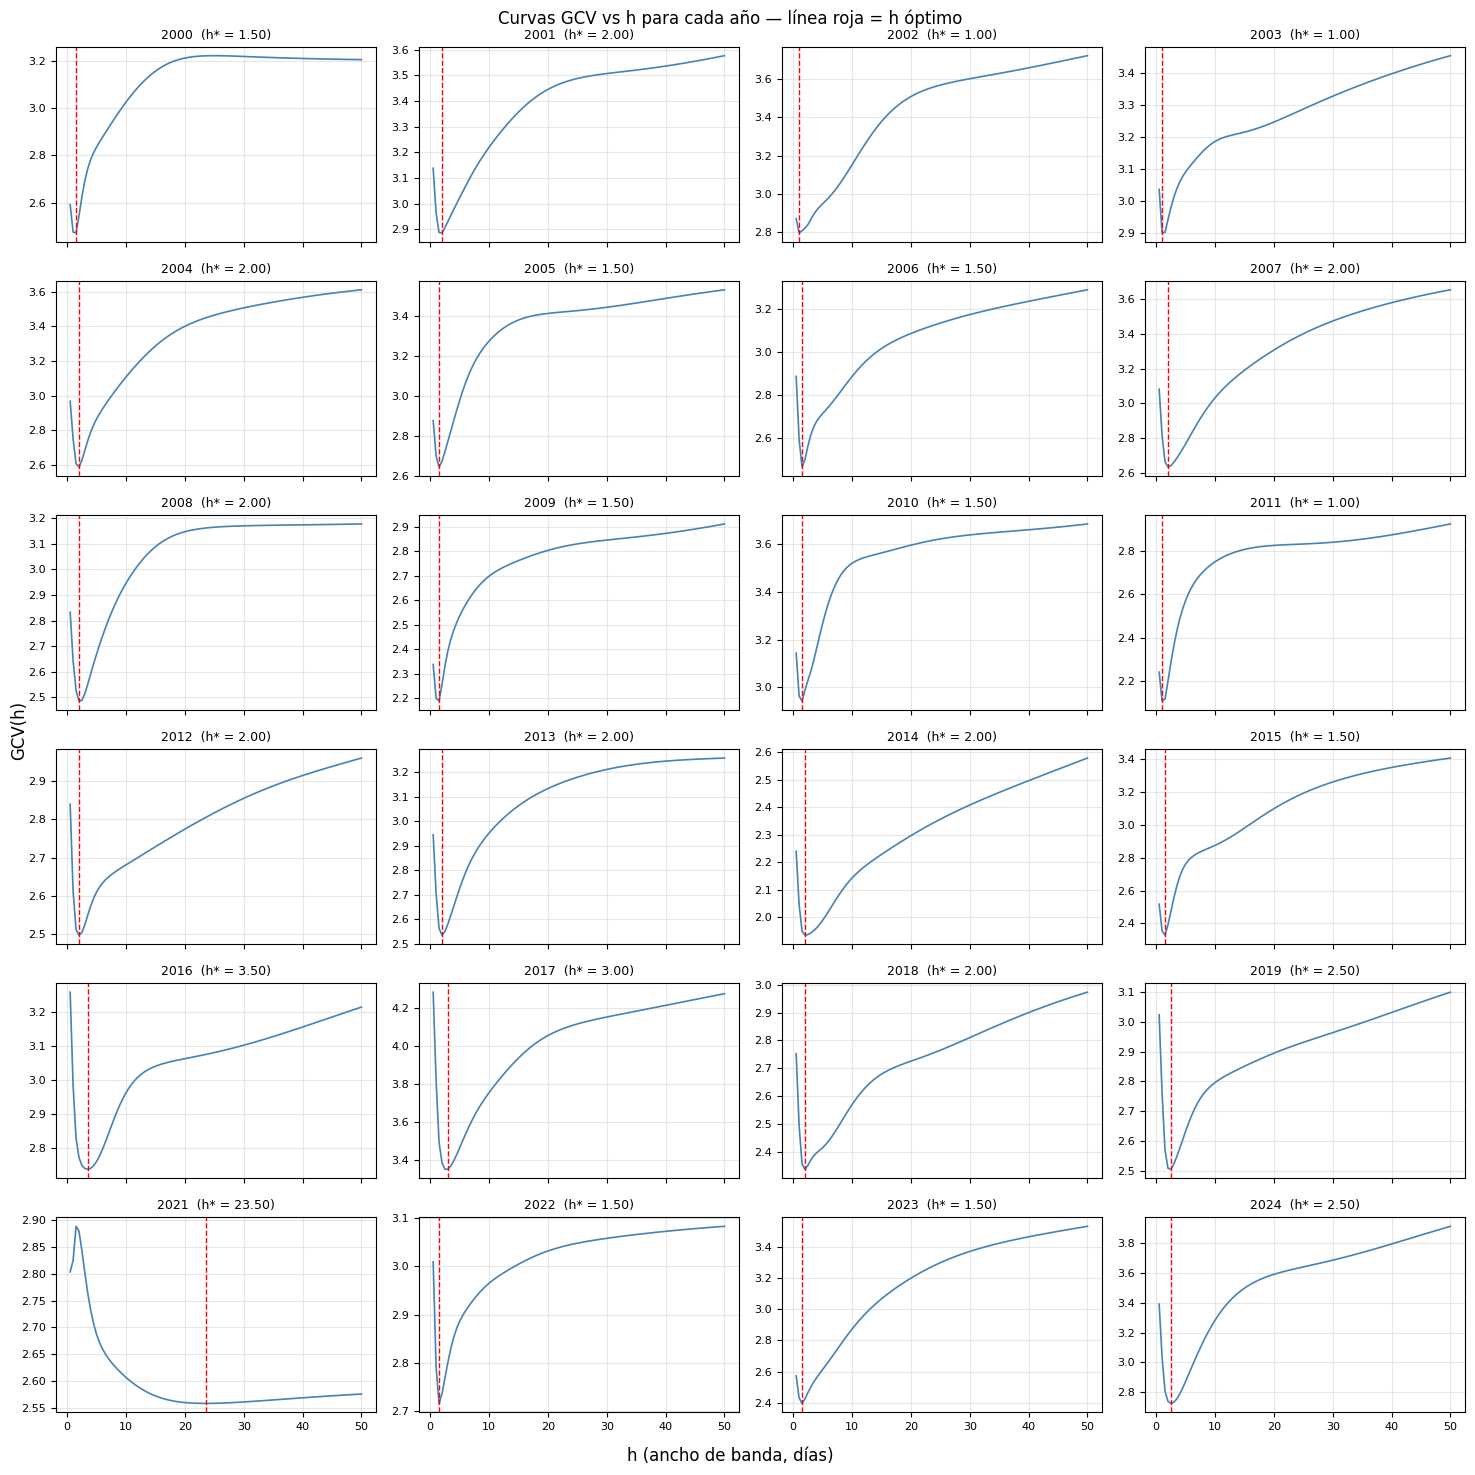

In [ ]:
years_disp = sorted(resultados.keys())
n_years    = len(years_disp)

n_cols = 4
n_rows = int(np.ceil(n_years / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 2.5 * n_rows), sharex=True)
axes = axes.flatten()

for k, year in enumerate(years_disp):
    ax  = axes[k]
    res = resultados[year]
    ax.plot(h_grid, res['gcvs'], color='steelblue', linewidth=1.2)
    ax.axvline(res['h_opt'], color='red', linestyle='--', linewidth=1)
    ax.set_title(f"{year}  (h* = {res['h_opt']:.2f})", fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=8)

# Apagar los ejes sobrantes
for k in range(len(years_disp), len(axes)):
    axes[k].axis('off')

fig.supxlabel('h (ancho de banda, días)')
fig.supylabel('GCV(h)')
fig.suptitle('Curvas GCV vs h para cada año — línea roja = h óptimo', fontsize=12)
plt.tight_layout()
plt.show()

Todas las curvas tienen forma de "U" o "L" con un mínimo claro a la izquierda. Ninguna cayó en el extremo de la malla, lo que confirma la robustez de la selección.

Sin embargo, llama la atención el caso de **2021, donde $h^* \approx 23$**, mucho mayor que el resto (1–3 días). Antes de superponer las curvas de regresión, vale la pena visualizar cómo están distribuidos los días disponibles en cada año.

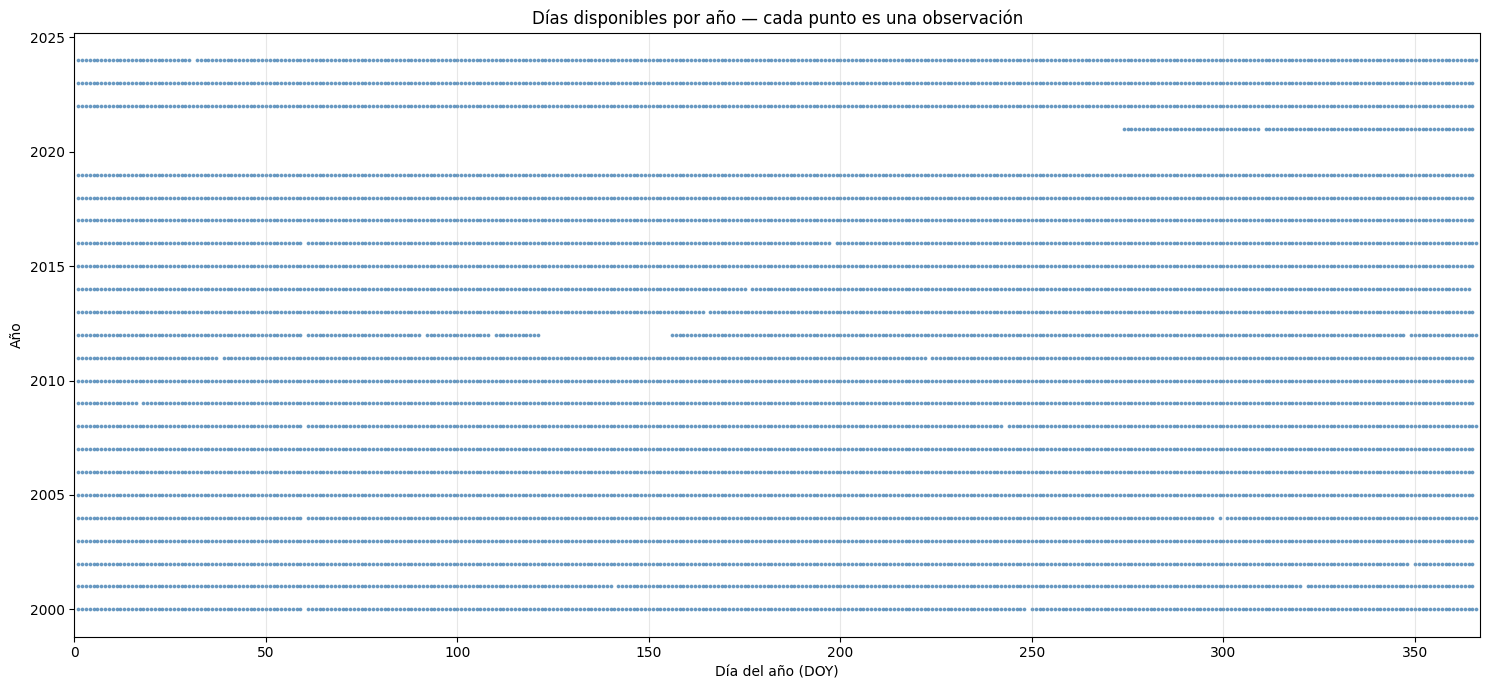

In [ ]:
# Visualizar la dispersión de los DOY observados por año
fig, ax = plt.subplots(figsize=(15, 7))

for year in years_disp:
    X = resultados[year]['X']
    ax.scatter(X, [year] * len(X), s=3, color='steelblue', alpha=0.7)

ax.set_xlabel('Día del año (DOY)')
ax.set_ylabel('Año')
ax.set_title('Días disponibles por año — cada punto es una observación')
ax.set_xlim(0, 367)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

La gráfica anterior revela que en 2021 los 91 datos disponibles están concentrados únicamente en el **último trimestre del año** (octubre–diciembre), mientras que los demás años cubren los 365 días completos. Esto explica el $h^*$ atípicamente grande por tres razones combinadas:

1. **Menos datos:** según la teoría (Clase 4b, diap. 32), el ancho de banda óptimo escala como $h^* \propto n^{-1/5}$. Con $n = 91$ en lugar de $n \approx 360$, el $h$ óptimo es naturalmente mayor.
2. **Rango temporal corto:** al cubrir solo 91 días, no hay ciclo anual completo que capturar. No tiene sentido buscar variabilidad fina; el suavizador prefiere una curva casi recta sobre esos tres meses.
3. **Penalización de GCV con $n$ pequeño:** el factor $(1 - \nu/n)^2$ del denominador castiga fuertemente la flexibilidad cuando $n$ es pequeño, empujando hacia $h$ grandes.

Esto se refleja en $\nu^* \approx 2$ para 2021 (vs. $\nu^* \approx 100$ en otros años): GCV está reconociendo honestamente que con tan pocos datos y un rango tan corto, lo más razonable es un ajuste casi lineal de apenas 2 grados de libertad.


### 7. Visualización: superposición de las 25 curvas anuales

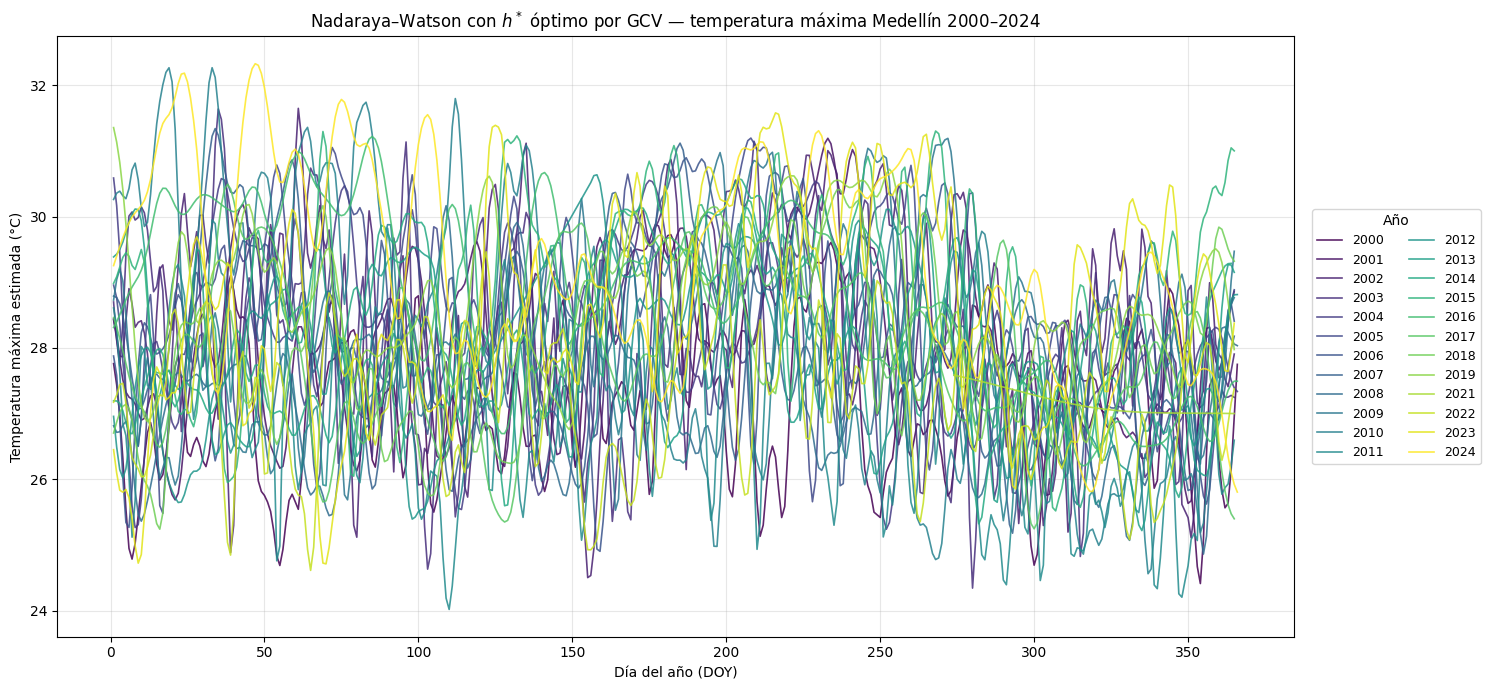

In [ ]:
cmap    = plt.cm.viridis
colores = cmap(np.linspace(0, 1, n_years))

# ── Gráfica 1: curvas con h* óptimo de GCV ──────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 7))
for i, year in enumerate(years_disp):
    res      = resultados[year]
    idx_sort = np.argsort(res['X'])
    ax.plot(res['X'][idx_sort], res['Y_hat'][idx_sort],
            color=colores[i], linewidth=1.2, alpha=0.85, label=str(year))

ax.set_xlabel('Día del año (DOY)')
ax.set_ylabel('Temperatura máxima estimada (°C)')
ax.set_title('Nadaraya–Watson con $h^*$ óptimo por GCV — temperatura máxima Medellín 2000–2024')
ax.grid(True, alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), ncol=2, fontsize=9, title='Año')
plt.tight_layout()
plt.show()

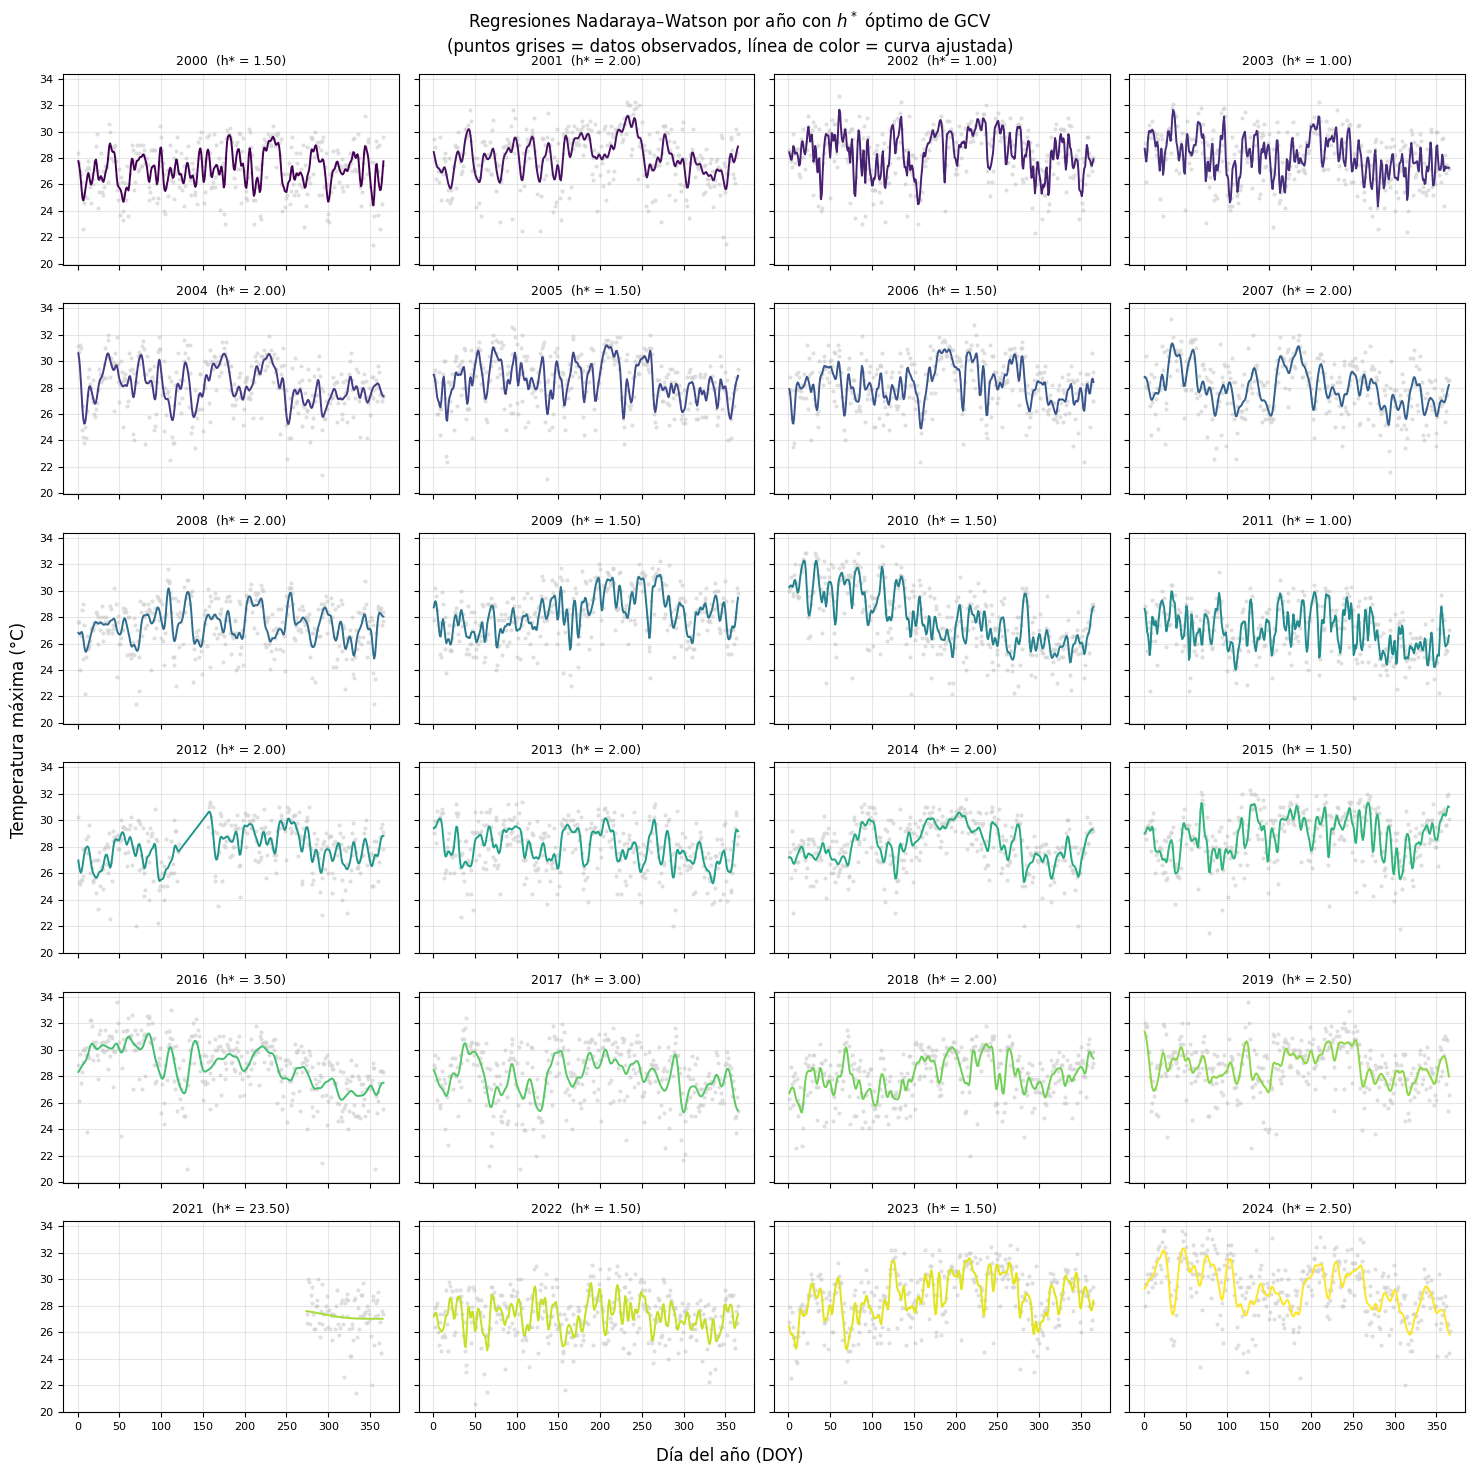

In [ ]:
# Una regresión por año en sub-paneles separados (con h* óptimo de GCV)
n_cols = 4
n_rows = int(np.ceil(n_years / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 2.5 * n_rows),
                         sharex=True, sharey=True)
axes = axes.flatten()

for k, year in enumerate(years_disp):
    ax       = axes[k]
    res      = resultados[year]
    idx_sort = np.argsort(res['X'])
    ax.scatter(res['X'], res['Y'], s=4, color='lightgray', alpha=0.6)
    ax.plot(res['X'][idx_sort], res['Y_hat'][idx_sort],
            color=colores[k], linewidth=1.4)
    ax.set_title(f"{year}  (h* = {res['h_opt']:.2f})", fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=8)

# Apagar ejes sobrantes
for k in range(len(years_disp), len(axes)):
    axes[k].axis('off')

fig.supxlabel('Día del año (DOY)')
fig.supylabel('Temperatura máxima (°C)')
fig.suptitle('Regresiones Nadaraya–Watson por año con $h^*$ óptimo de GCV\n'
             '(puntos grises = datos observados, línea de color = curva ajustada)',
             fontsize=12)
plt.tight_layout()
plt.show()

> **Nota:** En las gráficas anteriores aparecen 24 curvas en lugar de 25 porque el año **2020 no tiene datos** en el dataset y por tanto no se pudo ajustar.

Las curvas son rugosas porque GCV escogió $h$ pequeños (~1–3 días): es el balance sesgo-varianza óptimo para temperaturas diarias, que tienen mucha variabilidad natural.

**Observaciones de los paneles individuales:**

- En la mayoría de años (con $h^* \approx 1$–$3$ días) las curvas siguen muy de cerca la nube de puntos, capturando incluso la variabilidad diaria.
- Los años con $h^*$ ligeramente mayores (2016, 2017, 2019, 2024 con $h^* \in [2.5, 3.5]$) muestran curvas un poco más suaves.
- **2021 destaca claramente**: la curva solo cubre el tramo octubre–diciembre y es casi una línea recta, consistente con el $h^* \approx 23$ y $\nu^* \approx 2$ que vimos.
- En todos los años la curva ajustada pasa por el centro de la nube de puntos, sin sesgos visibles en los extremos.

Para apreciar la **tendencia estacional global** y comparar el nivel medio entre años, graficamos también con un $h$ fijo más grande (solo con fines visuales, **no reemplaza** el ajuste óptimo).

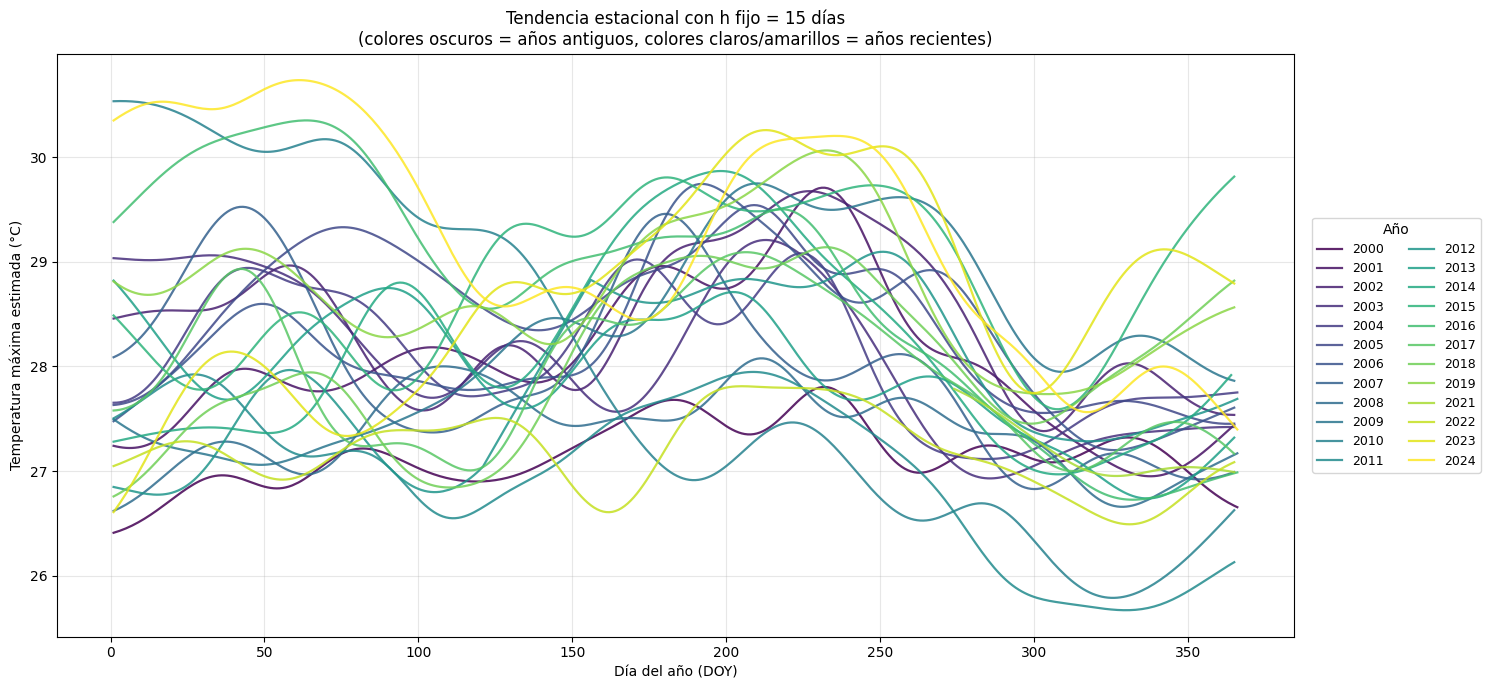

In [ ]:
# ── Gráfica 2: h fijo grande, solo para visualizar tendencia estacional ──────
h_visual = 15   # ~15 días

fig, ax = plt.subplots(figsize=(15, 7))
for i, year in enumerate(years_disp):
    res      = resultados[year]
    L_vis    = matriz_L(res['X'], h_visual)
    Y_vis    = L_vis @ res['Y']
    idx_sort = np.argsort(res['X'])
    ax.plot(res['X'][idx_sort], Y_vis[idx_sort],
            color=colores[i], linewidth=1.6, alpha=0.85, label=str(year))

ax.set_xlabel('Día del año (DOY)')
ax.set_ylabel('Temperatura máxima estimada (°C)')
ax.set_title(f'Tendencia estacional con h fijo = {h_visual} días\n'
             '(colores oscuros = años antiguos, colores claros/amarillos = años recientes)')
ax.grid(True, alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), ncol=2, fontsize=9, title='Año')
plt.tight_layout()
plt.show()

**Interpretación de las curvas:**

- Se distingue el **patrón bimodal** del clima de Medellín: picos en enero–marzo y julio–septiembre, valles en los meses lluviosos (abril–mayo y octubre–noviembre).
- Las curvas de años recientes (**tonos claros/amarillos, 2022–2024**) tienden a estar **por encima** de los años antiguos (azul–morado oscuro, 2000–2005), sugiriendo un calentamiento progresivo.

**Efecto de los huecos del dataset sobre el suavizado:**  
En zonas donde un año tiene muchos días faltantes consecutivos, Nadaraya–Watson tiene menos vecinos disponibles y el ajuste "salta" a través del hueco usando puntos más lejanos, produciendo **curvas anormalmente suaves o desplazadas** en esos tramos. Es especialmente notable en **2021** (solo datos de octubre–diciembre) y **2012** (37 días faltantes dispersos). Es una limitación del estado original del dataset, no del método.

---
## Parte 2: Prueba de Wilcoxon Signed-Rank en datos pareados

### 8. Planteamiento

Para cada año $a \in \{2000, \dots, 2023\}$ se forman diferencias pareadas día a día con 2024:

$$d_i = T_{2024}(\text{mes}_i, \text{día}_i) - T_a(\text{mes}_i, \text{día}_i)$$

Solo se usan los días comunes entre el año $a$ y 2024. Se eliminan los $d_i = 0$ (empates).

El test contrasta:
$$H_0: \theta = 0 \quad \text{vs.} \quad H_1: \theta \neq 0$$

donde $\theta$ es la mediana de las diferencias.

#### Estadístico de prueba

Según las diapositivas, el estadístico clásico de Wilcoxon Signed-Rank se calcula así:

1. Se rankean los valores absolutos $|d_i|$ → rangos $R_i$.
2. Se calculan dos sumas:
   $$W^+ = \sum_{d_i > 0} R_i, \qquad W^- = \sum_{d_i < 0} R_i$$
3. El estadístico clásico es $W = \min(W^+, W^-)$.

**`scipy.stats.wilcoxon`** por defecto reporta como estadístico la suma de rangos del **signo menos frecuente**, equivalente a $\min(W^+, W^-)$. Coincide con la definición de las diapositivas.

#### Cómo decidir si un año fue más caluroso que 2024

El test de Wilcoxon solo nos dice si las distribuciones son distintas, no en qué dirección. Por eso, **una vez que se rechaza $H_0$**, comparamos las sumas de rangos para determinar el sentido del efecto:

- Si $W^+ > W^-$ → predominan diferencias positivas → **2024 fue más cálido**.
- Si $W^- > W^+$ → predominan diferencias negativas → **el año $a$ fue más cálido**.

Esta comparación es más coherente con el test que usar la media, porque Wilcoxon trabaja con rangos. Si $H_0$ no se rechaza, la comparación entre $W^+$ y $W^-$ no es informativa.


### 9. Aplicación del test

Reutilizamos `datos_anuales` (que ya tiene los años filtrados y con el 29-feb eliminado en bisiestos).
Para emparejar usamos la pareja `(mes, día)` como llave.

In [ ]:
# Tabla de temperaturas de 2024 indexada por (mes, día)
df_2024   = datos_anuales[2024]['df']
temp_2024 = df_2024.set_index(
    pd.MultiIndex.from_arrays([df_2024['Fecha'].dt.month, df_2024['Fecha'].dt.day],
                              names=['mes', 'dia'])
)['Temperatura']

print(f"Días disponibles en 2024: {len(temp_2024)}")

Días disponibles en 2024: 365


In [ ]:
filas_w = []

for year in range(2000, 2024):
    if year not in datos_anuales:
        filas_w.append({
            'Año': year, 'n_pareados': 0,
            'W_estadistico': np.nan, 'W_plus': np.nan, 'W_minus': np.nan,
            'p_valor': np.nan, 'mediana_dif': np.nan,
        })
        continue

    df_year   = datos_anuales[year]['df']
    temp_year = df_year.set_index(
        pd.MultiIndex.from_arrays([df_year['Fecha'].dt.month, df_year['Fecha'].dt.day],
                                  names=['mes', 'dia'])
    )['Temperatura']

    # Días comunes con 2024
    dias_comunes = temp_year.index.intersection(temp_2024.index)

    # Diferencias d_i = T_2024 - T_year
    diffs = (temp_2024.loc[dias_comunes] - temp_year.loc[dias_comunes]).values
    diffs = diffs[diffs != 0]                       # eliminar empates

    if len(diffs) >= 1:
        # Estadístico Wilcoxon = min(W+, W-) según scipy
        W_stat, pval = wilcoxon(diffs, alternative='two-sided')

        # Calcular W+ y W- explícitamente para ver el signo dominante
        rangos  = pd.Series(np.abs(diffs)).rank().values
        W_plus  = rangos[diffs > 0].sum()
        W_minus = rangos[diffs < 0].sum()
    else:
        W_stat = pval = W_plus = W_minus = np.nan

    filas_w.append({
        'Año':            year,
        'n_pareados':     len(diffs),
        'W_estadistico':  W_stat,
        'W_plus':         W_plus,
        'W_minus':        W_minus,
        'p_valor':        pval,
        'mediana_dif':    np.median(diffs) if len(diffs) > 0 else np.nan,
    })

df_w = pd.DataFrame(filas_w)

# Decisión y dirección
df_w['Rechaza_H0']     = df_w['p_valor'] < 0.05
df_w['Año_mas_calido'] = np.where(df_w['W_plus'] > df_w['W_minus'], '2024',
                          np.where(df_w['W_plus'] < df_w['W_minus'],
                                   df_w['Año'].astype(str), '—'))

# Tabla final ordenada
df_w_show = df_w[['Año', 'n_pareados', 'W_estadistico', 'W_plus', 'W_minus',
                  'p_valor', 'mediana_dif', 'Rechaza_H0', 'Año_mas_calido']].copy()
df_w_show = df_w_show.round({'W_estadistico': 1, 'W_plus': 1, 'W_minus': 1,
                              'p_valor': 6, 'mediana_dif': 3})
df_w_show.set_index('Año')

,n_pareados,W_estadistico,W_plus,W_minus,p_valor,mediana_dif,Rechaza_H0,Año_mas_calido
Año,,,,,,,,
2000,359,9753.0,54867.0,9753.0,0.000000,2.10,True,2024
2001,358,18767.5,45493.5,18767.5,0.000000,1.00,True,2024
2002,358,21444.0,42817.0,21444.0,0.000000,1.00,True,2024
2003,361,17606.0,47735.0,17606.0,0.000000,1.30,True,2024
2004,353,17937.5,44543.5,17937.5,0.000000,1.20,True,2024
2005,354,21501.0,41334.0,21501.0,0.000000,0.80,True,2024
2006,355,19019.0,44171.0,19019.0,0.000000,1.20,True,2024
2007,360,16677.0,48303.0,16677.0,0.000000,1.40,True,2024
2008,356,11153.5,52392.5,11153.5,0.000000,1.90,True,2024


**Cómo leer la tabla:**

- **W_estadistico:** $\min(W^+, W^-)$ reportado por `scipy.stats.wilcoxon` (coincide con la definición de las diapositivas).
- **W_plus, W_minus:** sumas de rangos de diferencias positivas y negativas. La mayor indica el sentido dominante.
- **p_valor:** valor-p del test bilateral.
- **mediana_dif:** mediana de $d_i = T_{2024} - T_a$, valor de referencia.
- **Rechaza_H0:** True si $p < 0.05$.
- **Año_mas_calido:** según $W^+$ vs $W^-$. Si $W^+ > W^-$ → predominan diferencias positivas → 2024 fue más cálido.

En la siguiente sección visualizamos los p-valores e interpretamos los resultados globalmente.

### 10. Visualización de p-valores

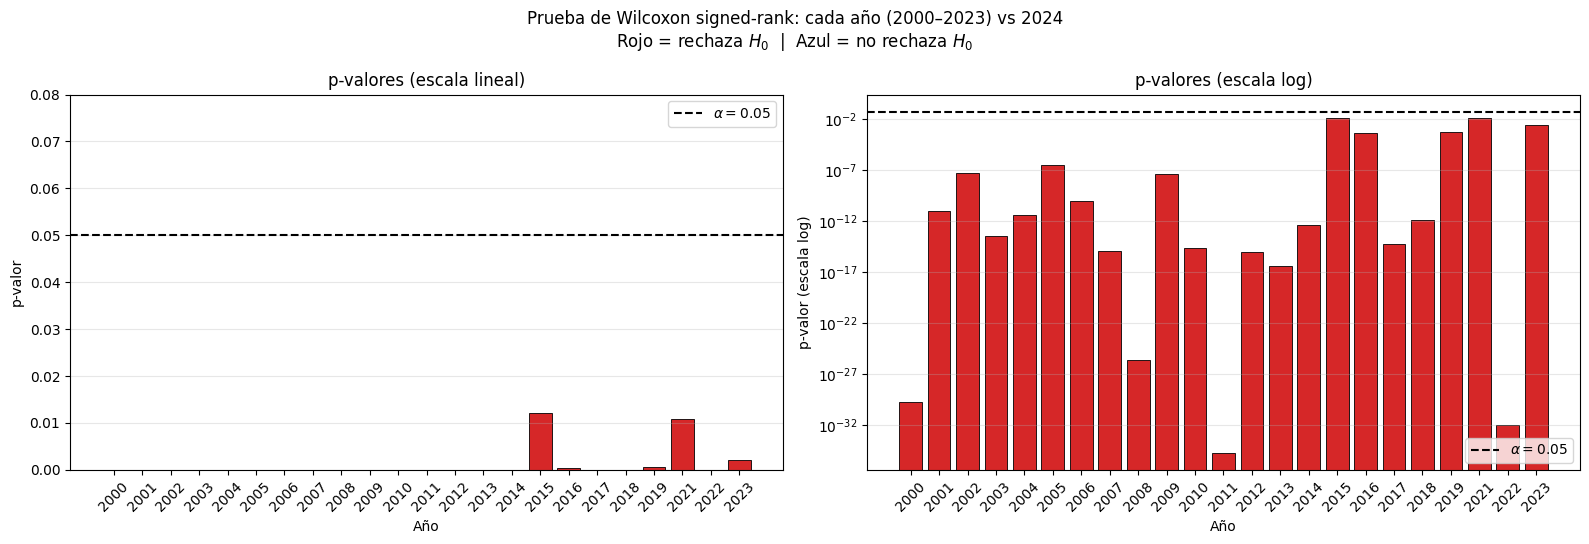

In [ ]:
df_plot       = df_w.dropna(subset=['p_valor']).copy()
colores_barra = ['#d62728' if r else '#1f77b4' for r in df_plot['Rechaza_H0']]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel izquierdo: escala lineal
ax = axes[0]
ax.bar(df_plot['Año'].astype(str), df_plot['p_valor'],
       color=colores_barra, edgecolor='black', linewidth=0.6)
ax.axhline(0.05, color='black', linestyle='--', linewidth=1.5, label=r'$\alpha = 0.05$')
ax.set_xlabel('Año'); ax.set_ylabel('p-valor')
ax.set_title('p-valores (escala lineal)')
ax.set_ylim(0, 0.08); ax.legend(); ax.tick_params(axis='x', rotation=45)
ax.grid(True, axis='y', alpha=0.3)

# Panel derecho: escala logarítmica
ax = axes[1]
ax.bar(df_plot['Año'].astype(str), df_plot['p_valor'],
       color=colores_barra, edgecolor='black', linewidth=0.6)
ax.axhline(0.05, color='black', linestyle='--', linewidth=1.5, label=r'$\alpha = 0.05$')
ax.set_yscale('log')
ax.set_xlabel('Año'); ax.set_ylabel('p-valor (escala log)')
ax.set_title('p-valores (escala log)')
ax.legend(loc='lower right'); ax.tick_params(axis='x', rotation=45)
ax.grid(True, axis='y', alpha=0.3, which='both')

fig.suptitle('Prueba de Wilcoxon signed-rank: cada año (2000–2023) vs 2024\n'
             'Rojo = rechaza $H_0$  |  Azul = no rechaza $H_0$', fontsize=12)
plt.tight_layout()
plt.show()

### 11. Discusión y respuesta a la pregunta

**¿Existe evidencia estadística de que las temperaturas han cambiado? ¿A partir de qué año?**

Sí, la evidencia es contundente:

- **Se rechaza $H_0$ en todos los años con datos**, sin excepción.
- **$W^+ \gg W^-$ en todos los casos**: las diferencias positivas dominan ampliamente, indicando que **2024 fue sistemáticamente más cálido** que cualquier año anterior.
- Los p-valores están **muy alejados del nivel de significancia** $\alpha = 0.05$ (escala de $10^{-3}$ a $10^{-35}$), por lo que el rechazo de $H_0$ tiene **mucha fuerza**: bajo la hipótesis nula sería virtualmente imposible observar diferencias tan extremas.

No hay un año "umbral" a partir del cual aparezca la diferencia: el contraste 2024 vs. cualquier año previo es significativo desde 2000. Lo que sí varía es la **magnitud** de la diferencia: más grande contra años antiguos, más pequeña contra años recientes, consistente con un **calentamiento progresivo**.

**Consideraciones sobre el tamaño de muestra y valores faltantes:**

El tamaño de la muestra y la cantidad de valores faltantes pueden afectar tanto la significancia estadística como la fuerza de la prueba. No obstante, el tamaño muestral para cada año, de acuerdo con el material de clase, es suficientemente grande y se obtuvieron resultados consistentes. Para 2021 ($n \approx 91$) y 2012 ($n \approx 329$), el test compara solo los días comunes con 2024. Si los días disponibles corresponden a una estación específica, la comparación puede estar sesgada hacia esa temporada y debe interpretarse con cautela.

Adicionalmente, el año **2020 no pudo ser analizado** porque no tiene datos en el dataset, por lo que queda fuera de la comparación con 2024.

# Ejercicio 3: Profundidad Multivariada en $\mathbb{R}^2$

## 1. Simulación de Datos

Generaremos una muestra de aproximadamente 290 puntos en $\mathbb{R}^2$ que contenga dos clusters:

- **Cluster 1 (mayoritario):** 160 puntos, distribución normal multivariada con media $(8,8)$ y matriz de covarianza que produce un elipsoide orientado a lo largo de $y = x$.
- **Cluster 2:** 130 puntos, distribución normal multivariada con media $(18,12)$ y dispersión moderada.

Se graficarán los datos para visualizar los clusters.

In [ ]:
# Importar librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fijar semilla para reproducibilidad
np.random.seed(42)

# Parámetros del Cluster 1 (mayoritario)
mean1 = [8, 8]
cov1 = [[4, 3.5], [3.5, 4]]  # Elipsoide orientado a lo largo de y = x
n1 = 160

# Parámetros del Cluster 2
mean2 = [18, 12]
cov2 = [[6, 0], [0, 3]]  # Dispersión moderada
n2 = 130

# Generar datos
cluster1 = np.random.multivariate_normal(mean1, cov1, n1)
cluster2 = np.random.multivariate_normal(mean2, cov2, n2)

# Crear DataFrame
X = np.vstack([cluster1, cluster2])
labels = np.array([0]*n1 + [1]*n2)
df = pd.DataFrame(X, columns=["x1", "x2"])
df["cluster"] = labels

df.tail()

,x1,x2,cluster
285,18.045116,14.903675,1
286,18.800805,11.620507,1
287,20.031620,8.170201,1
288,18.577135,13.335178,1
289,14.378218,13.981040,1


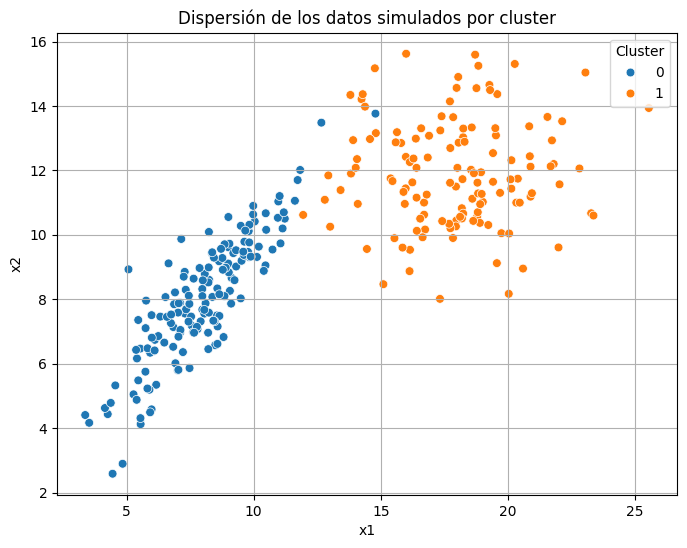

In [ ]:
# Visualización de los datos simulados
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="x1", y="x2", hue="cluster", palette=["#1f77b4", "#ff7f0e"], s=40)
plt.title("Dispersión de los datos simulados por cluster")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

## 2. Cálculo de Profundidades

Calculemos la profundidad para cada punto usando las tres medidas:

- **Profundidad de Tukey:** Utiliza la función `scipy.stats.halfspace_depth` (o una implementación alternativa si no está disponible).
- **Profundidad Simplicial:** Se estima mediante un método Monte Carlo (por ejemplo, 2000 tríos aleatorios).
- **Profundidad k-NN:** Se calcula usando la fórmula dada, con $k=10$ y $k=20$ para comparar.

Se explicará cada método antes de su implementación.

### 2.1 Profundidad de Tukey (Half-Space Depth)

La profundidad de Tukey de un punto es el mínimo número de puntos de la muestra que quedan en un semiespacio determinado por una recta que pasa por el punto. Es una medida robusta de centralidad multivariada.

Implementaremos una función aproximada para calcular la profundidad de Tukey en $\mathbb{R}^2$ usando direcciones aleatorias (Monte Carlo).

In [ ]:
# Función para calcular la profundidad de Tukey aproximada

def tukey_depth(X, point, n_directions=2000):
    X = np.asarray(X)
    point = np.asarray(point)
    n = X.shape[0]
    min_count = n
    for _ in range(n_directions):
        # Dirección aleatoria en el círculo unitario
        theta = np.random.uniform(0, 2*np.pi)
        v = np.array([np.cos(theta), np.sin(theta)])
        # Proyecciones
        proj = (X - point) @ v
        count_pos = np.sum(proj > 0)
        count_neg = np.sum(proj < 0)
        min_count = min(min_count, count_pos, count_neg)
    return min_count / n

# Calcular profundidad de Tukey para todos los puntos
df["tukey_depth_raw"] = df[["x1", "x2"]].apply(lambda row: tukey_depth(X, row.values), axis=1)

# Normalizar Tukey a [0, 1] usando min-max normalization
tukey_min = df["tukey_depth_raw"].min()
tukey_max = df["tukey_depth_raw"].max()
df["tukey_depth"] = (df["tukey_depth_raw"] - tukey_min) / (tukey_max - tukey_min)

print(f"Profundidad Tukey - Rango original: [{tukey_min:.4f}, {tukey_max:.4f}]")
print(f"Profundidad Tukey - Rango normalizado: [{df['tukey_depth'].min():.4f}, {df['tukey_depth'].max():.4f}]")
df[["x1", "x2", "tukey_depth"]].head()

Profundidad Tukey - Rango original: [0.0000, 0.3966]
Profundidad Tukey - Rango normalizado: [0.0000, 1.0000]


,x1,x2,tukey_depth
0,7.107249,6.968985,0.339130
1,5.984242,7.507271,0.043478
2,8.570505,8.336368,0.773913
3,4.558150,5.325585,0.034783
4,8.637853,9.180413,0.373913


### 2.2 Profundidad Simplicial

La profundidad simplicial de un punto es la proporción de todos los tríos posibles de la muestra cuyo triángulo contiene al punto. Se estima por Monte Carlo generando muchos tríos aleatorios y verificando si el punto está dentro del triángulo formado por cada trío.

In [ ]:
# Función para verificar si un punto está dentro de un triángulo
def point_in_triangle(pt, v1, v2, v3):
    # Barycentric coordinates
    def sign(p1, p2, p3):
        return (p1[0] - p3[0]) * (p2[1] - p3[1]) - (p2[0] - p3[0]) * (p1[1] - p3[1])
    b1 = sign(pt, v1, v2) < 0.0
    b2 = sign(pt, v2, v3) < 0.0
    b3 = sign(pt, v3, v1) < 0.0
    return ((b1 == b2) and (b2 == b3))

# Profundidad simplicial estimada por Monte Carlo
def simplicial_depth(X, point, n_trials=2000):
    X = np.asarray(X)
    n = X.shape[0]
    count = 0
    for _ in range(n_trials):
        idx = np.random.choice(n, 3, replace=False)
        v1, v2, v3 = X[idx]
        if point_in_triangle(point, v1, v2, v3):
            count += 1
    return count / n_trials

# Calcular profundidad simplicial para todos los puntos
df["simplicial_depth_raw"] = df[["x1", "x2"]].apply(lambda row: simplicial_depth(X, row.values), axis=1)

# Normalizar Simplicial a [0, 1] usando min-max normalization
simplicial_min = df["simplicial_depth_raw"].min()
simplicial_max = df["simplicial_depth_raw"].max()
df["simplicial_depth"] = (df["simplicial_depth_raw"] - simplicial_min) / (simplicial_max - simplicial_min)

print(f"Profundidad Simplicial - Rango original: [{simplicial_min:.4f}, {simplicial_max:.4f}]")
print(f"Profundidad Simplicial - Rango normalizado: [{df['simplicial_depth'].min():.4f}, {df['simplicial_depth'].max():.4f}]")
df[["x1", "x2", "simplicial_depth"]].head()

Profundidad Simplicial - Rango original: [0.0025, 0.2605]
Profundidad Simplicial - Rango normalizado: [0.0000, 1.0000]


,x1,x2,simplicial_depth
0,7.107249,6.968985,0.412791
1,5.984242,7.507271,0.052326
2,8.570505,8.336368,0.717054
3,4.558150,5.325585,0.021318
4,8.637853,9.180413,0.377907


### 2.3 Profundidad k-NN

La profundidad k-NN de un punto es inversamente proporcional al área de la bola centrada en el punto que contiene a sus $k$ vecinos más cercanos. Se calcula como:

$$
D_k(x; X) = \frac{k}{n \cdot \pi r_k(x)^2}
$$

donde $r_k(x)$ es la distancia al $k$-ésimo vecino más cercano.

In [ ]:
from sklearn.neighbors import NearestNeighbors

# Función para calcular profundidad k-NN
def knn_depth(X, point, k):
    X = np.asarray(X)
    point = np.asarray(point).reshape(1, -1)
    n = X.shape[0]
    nbrs = NearestNeighbors(n_neighbors=k+1)  # k+1 para incluir el punto mismo
    nbrs.fit(X)
    dists, _ = nbrs.kneighbors(point)
    r_k = dists[0, -1]  # Distancia al k-ésimo vecino (excluye el punto mismo)
    if r_k < 1e-10:  # Evitar división por cero
        r_k = 1e-10
    area = np.pi * r_k**2
    return k / (n * area)

# Calcular profundidad k-NN para diferentes valores de k dentro del intervalo
knn_values = [3, 11, 20, 30, 40, 47, 50, 100]
knn_raw_cols = {}

for k in knn_values:
    col_name = f"knn_depth_{k}"
    knn_raw_cols[k] = f"{col_name}_raw"
    df[knn_raw_cols[k]] = df[["x1", "x2"]].apply(lambda row: knn_depth(X, row.values, k), axis=1)

# Normalizar todas las profundidades k-NN a [0, 1] usando min-max normalization
print("\nProfundidades k-NN - Rangos antes y después de normalización:")
for k in knn_values:
    raw_col = knn_raw_cols[k]
    norm_col = f"knn_depth_{k}"

    knn_min = df[raw_col].min()
    knn_max = df[raw_col].max()
    df[norm_col] = (df[raw_col] - knn_min) / (knn_max - knn_min)

    print(f"k={k:3d}: Original [{knn_min:.6f}, {knn_max:.6f}] → Normalizado [{df[norm_col].min():.4f}, {df[norm_col].max():.4f}]")

df[["x1", "x2", "knn_depth_11", "knn_depth_47"]].head()


Profundidades k-NN - Rangos antes y después de normalización:
k=  3: Original [0.000279, 0.148756] → Normalizado [0.0000, 1.0000]
k= 11: Original [0.000538, 0.057817] → Normalizado [0.0000, 1.0000]
k= 20: Original [0.000638, 0.045694] → Normalizado [0.0000, 1.0000]
k= 30: Original [0.000800, 0.042030] → Normalizado [0.0000, 1.0000]
k= 40: Original [0.000872, 0.038188] → Normalizado [0.0000, 1.0000]
k= 47: Original [0.000972, 0.036864] → Normalizado [0.0000, 1.0000]
k= 50: Original [0.001013, 0.035833] → Normalizado [0.0000, 1.0000]
k=100: Original [0.001112, 0.020169] → Normalizado [0.0000, 1.0000]


,x1,x2,knn_depth_11,knn_depth_47
0,7.107249,6.968985,0.540807,0.763872
1,5.984242,7.507271,0.319325,0.390000
2,8.570505,8.336368,0.513880,0.759174
3,4.558150,5.325585,0.102302,0.121576
4,8.637853,9.180413,0.638905,0.694733


## 3. Identificación del Punto Más Central

Para cada medida de profundidad, identificaremos el punto con mayor profundidad (el más central según cada criterio).

In [ ]:
# Identificar el punto más central según cada medida
def get_most_central(df, depth_col):
    idx = df[depth_col].idxmax()
    return df.loc[idx, ["x1", "x2", depth_col]]

central_tukey = get_most_central(df, "tukey_depth")
central_simplicial = get_most_central(df, "simplicial_depth")
central_knn3 = get_most_central(df, "knn_depth_3")
central_knn11 = get_most_central(df, "knn_depth_11")
central_knn20 = get_most_central(df, "knn_depth_20")
central_knn30 = get_most_central(df, "knn_depth_30")
central_knn40 = get_most_central(df, "knn_depth_40")
central_knn47 = get_most_central(df, "knn_depth_47")
central_knn50 = get_most_central(df, "knn_depth_50")
central_knn100 = get_most_central(df, "knn_depth_100")


print("Punto más central (Tukey):", central_tukey.values)
print("Punto más central (Simplicial):", central_simplicial.values)
print("Punto más central (k-NN, k=3):", central_knn3.values)
print("Punto más central (k-NN, k=11):", central_knn11.values)
print("Punto más central (k-NN, k=20):", central_knn20.values)
print("Punto más central (k-NN, k=30):", central_knn30.values)
print("Punto más central (k-NN, k=40):", central_knn40.values)
print("Punto más central (k-NN, k=47):", central_knn47.values)
print("Punto más central (k-NN, k=50):", central_knn50.values)
print("Punto más central (k-NN, k=100):", central_knn100.values)

Punto más central (Tukey): [10.74051178  9.54430515  1.        ]
Punto más central (Simplicial): [10.74051178  9.54430515  1.        ]
Punto más central (k-NN, k=3): [9.67779424 9.35573272 1.        ]
Punto más central (k-NN, k=11): [8.76924251 9.28250994 1.        ]
Punto más central (k-NN, k=20): [9.20073536 9.43298906 1.        ]
Punto más central (k-NN, k=30): [7.53847877 7.46403286 1.        ]
Punto más central (k-NN, k=40): [8.05876379 7.55528813 1.        ]
Punto más central (k-NN, k=47): [7.98181207 8.09913945 1.        ]
Punto más central (k-NN, k=50): [7.47197789 7.85729527 1.        ]
Punto más central (k-NN, k=100): [8.2468365  8.60394907 1.        ]


## 4. Visualización

Se realizarán las siguientes visualizaciones:

(a) Gráfica de dispersión de los datos, coloreando por cluster y resaltando los tres puntos más centrales según cada medida.

(b) Mapas de contorno para cada función de profundidad, mostrando los niveles de profundidad en el plano.

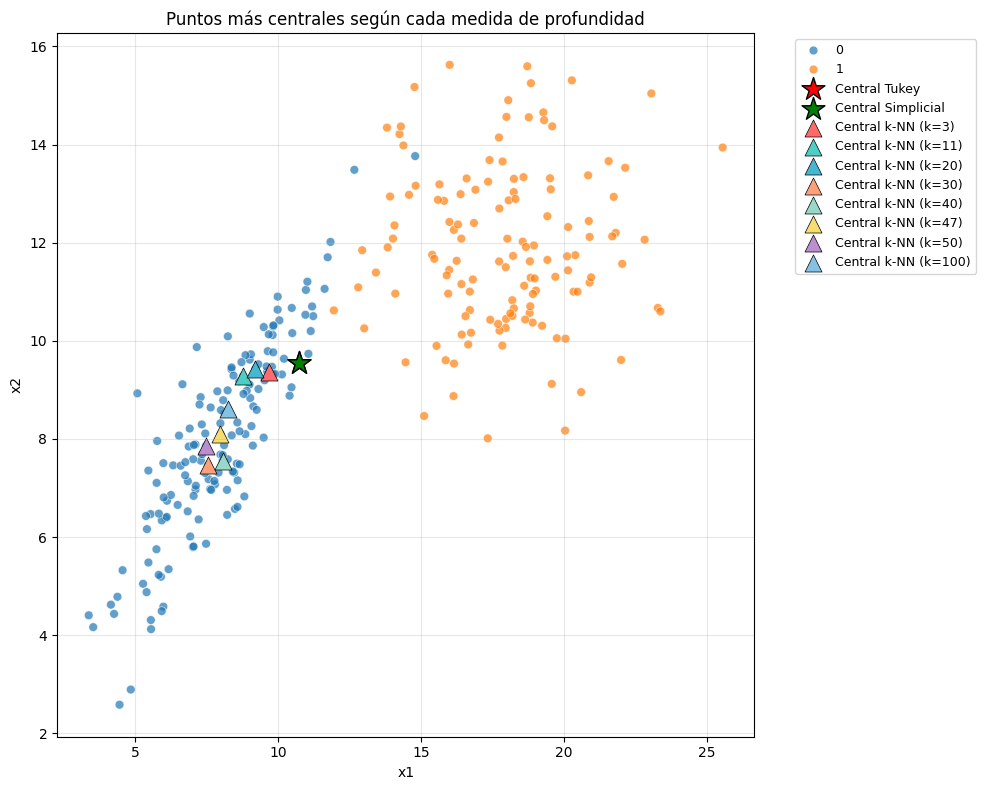

In [ ]:
# (a) Gráfica de dispersión resaltando los puntos más centrales
plt.figure(figsize=(10,8))
sns.scatterplot(data=df, x="x1", y="x2", hue="cluster", palette=["#1f77b4", "#ff7f0e"], s=40, alpha=0.7)
plt.scatter(central_tukey["x1"], central_tukey["x2"], c="red", marker="*", s=300, label="Central Tukey", edgecolors="black", linewidths=1)
plt.scatter(central_simplicial["x1"], central_simplicial["x2"], c="green", marker="*", s=300, label="Central Simplicial", edgecolors="black", linewidths=1)
plt.scatter(central_knn3["x1"], central_knn3["x2"], c="#FF6B6B", marker="^" , s=150, label="Central k-NN (k=3)", edgecolors="black", linewidths=0.5)
plt.scatter(central_knn11["x1"], central_knn11["x2"], c="#4ECDC4", marker="^" , s=150, label="Central k-NN (k=11)", edgecolors="black", linewidths=0.5)
plt.scatter(central_knn20["x1"], central_knn20["x2"], c="#45B7D1", marker="^" , s=150, label="Central k-NN (k=20)", edgecolors="black", linewidths=0.5)
plt.scatter(central_knn30["x1"], central_knn30["x2"], c="#FFA07A", marker="^" , s=150, label="Central k-NN (k=30)", edgecolors="black", linewidths=0.5)
plt.scatter(central_knn40["x1"], central_knn40["x2"], c="#98D8C8", marker="^" , s=150, label="Central k-NN (k=40)", edgecolors="black", linewidths=0.5)
plt.scatter(central_knn47["x1"], central_knn47["x2"], c="#F7DC6F", marker="^" , s=150, label="Central k-NN (k=47)", edgecolors="black", linewidths=0.5)
plt.scatter(central_knn50["x1"], central_knn50["x2"], c="#BB8FCE", marker="^" , s=150, label="Central k-NN (k=50)", edgecolors="black", linewidths=0.5)
plt.scatter(central_knn100["x1"], central_knn100["x2"], c="#85C1E2", marker="^" , s=150, label="Central k-NN (k=100)", edgecolors="black", linewidths=0.5)
plt.title("Puntos más centrales según cada medida de profundidad")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

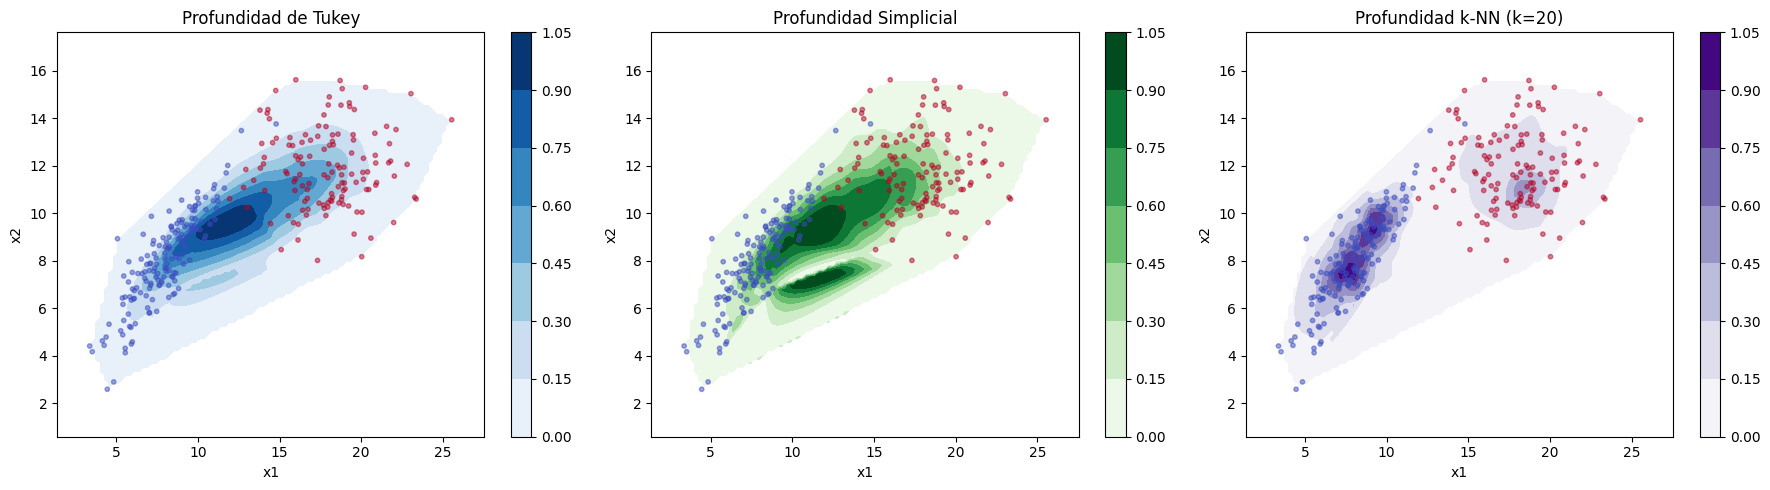

In [ ]:
# (b) Mapas de contorno de profundidad
from scipy.interpolate import griddata

# Crear una malla para evaluar las profundidades
grid_x, grid_y = np.meshgrid(
    np.linspace(df["x1"].min()-2, df["x1"].max()+2, 100),
    np.linspace(df["x2"].min()-2, df["x2"].max()+2, 100)
)
grid_points = np.c_[grid_x.ravel(), grid_y.ravel()]

# Interpolación de profundidades para cada método
grid_tukey = griddata(df[["x1", "x2"]].values, df["tukey_depth"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_simplicial = griddata(df[["x1", "x2"]].values, df["simplicial_depth"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn20 = griddata(df[["x1", "x2"]].values, df["knn_depth_20"].values, grid_points, method='cubic').reshape(grid_x.shape)

# Limitar los valores interpolados al rango [0, 1]
grid_tukey = np.clip(grid_tukey, 0, 1)
grid_simplicial = np.clip(grid_simplicial, 0, 1)
grid_knn20 = np.clip(grid_knn20, 0, 1)

# Graficar mapas de contorno
fig, axs = plt.subplots(1, 3, figsize=(18,5))
levels = 6

cs1 = axs[0].contourf(grid_x, grid_y, grid_tukey, levels=levels, cmap="Blues", vmin=0, vmax=1)
axs[0].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[0].set_title("Profundidad de Tukey")
fig.colorbar(cs1, ax=axs[0])

cs2 = axs[1].contourf(grid_x, grid_y, grid_simplicial, levels=levels, cmap="Greens", vmin=0, vmax=1)
axs[1].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[1].set_title("Profundidad Simplicial")
fig.colorbar(cs2, ax=axs[1])

cs3 = axs[2].contourf(grid_x, grid_y, grid_knn20, levels=levels, cmap="Purples", vmin=0, vmax=1)
axs[2].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[2].set_title("Profundidad k-NN (k=20)")
fig.colorbar(cs3, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
plt.tight_layout()
plt.show()

### Mapas de contorno comparativos para Profundidad k-NN con diferentes valores de k

Se crean gráficas de contorno para visualizar cómo varían las curvas de nivel de la profundidad k-NN conforme aumenta el valor de $k$. Esto permite observar el efecto del parámetro $k$ en la identificación de regiones centrales y en la suavidad de la función de profundidad.

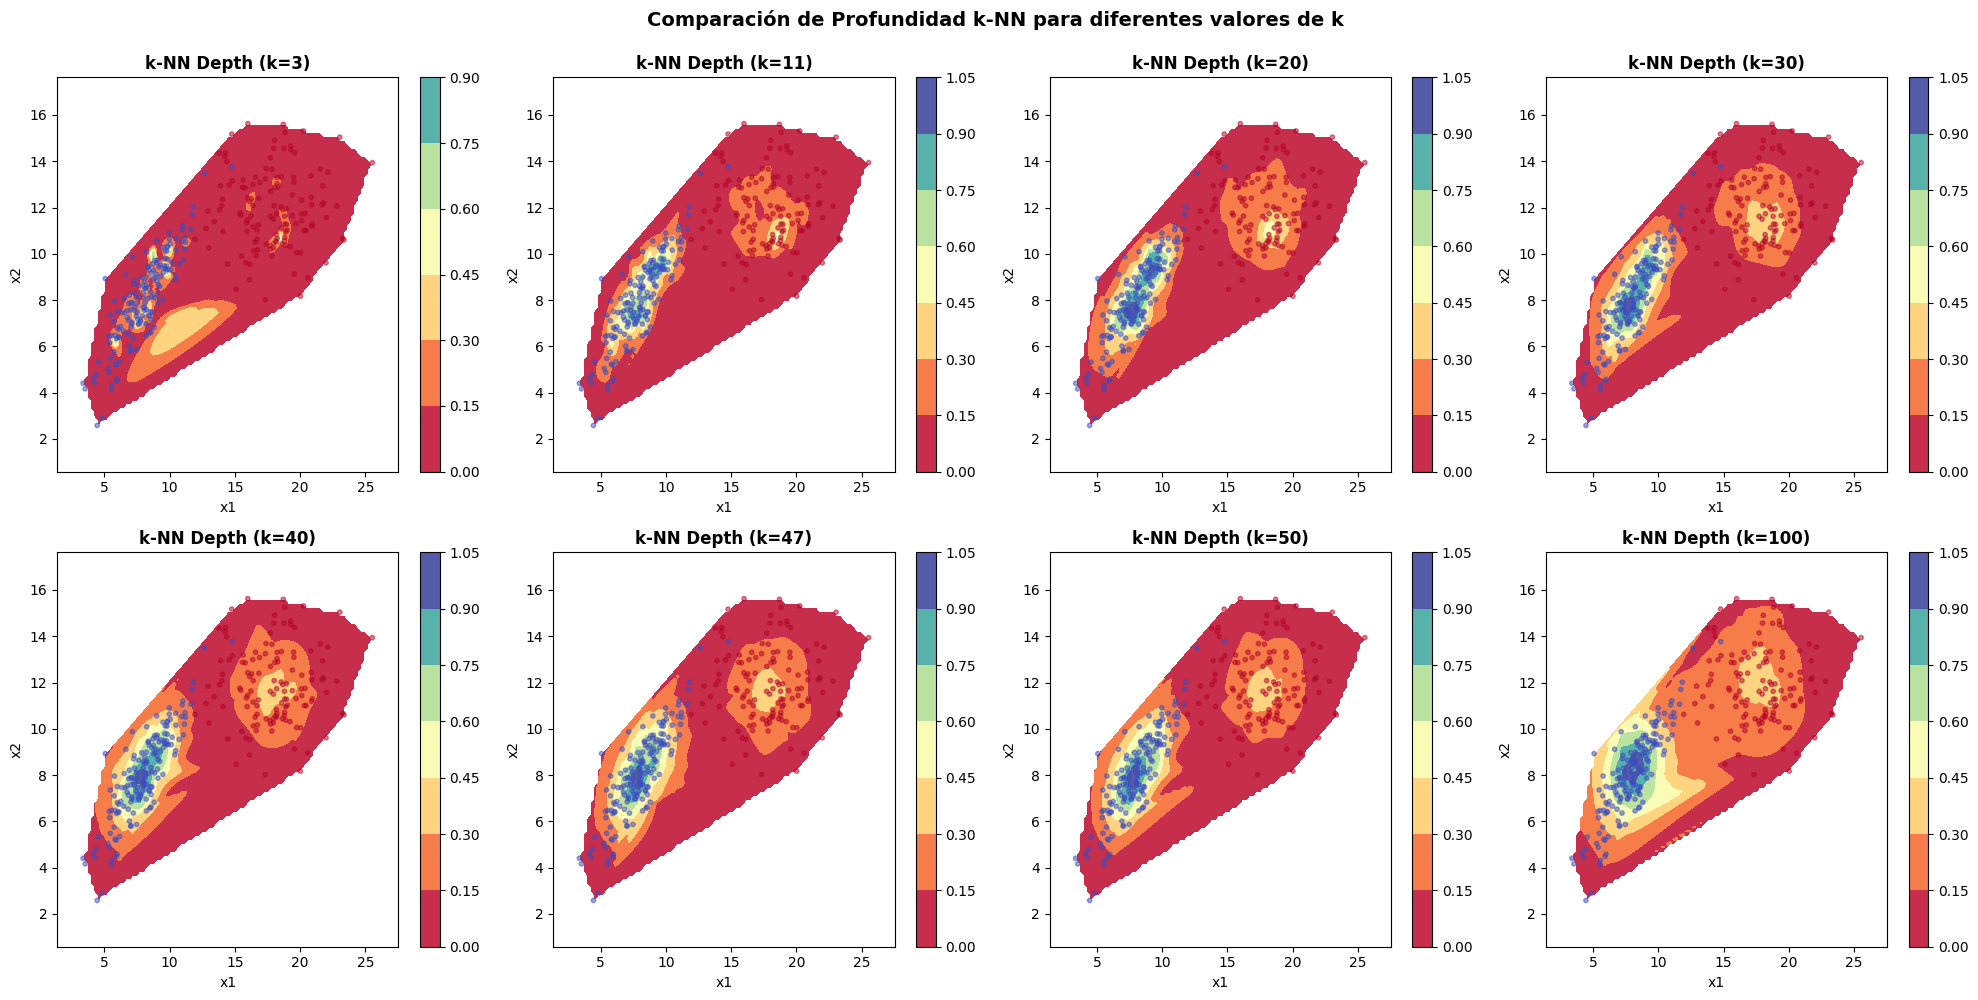

In [ ]:
# Mapas de contorno para k-NN con diferentes valores de k
# Interpolar profundidades para cada k
grid_knn3 = griddata(df[["x1", "x2"]].values, df["knn_depth_3"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn11 = griddata(df[["x1", "x2"]].values, df["knn_depth_11"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn20 = griddata(df[["x1", "x2"]].values, df["knn_depth_20"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn30 = griddata(df[["x1", "x2"]].values, df["knn_depth_30"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn40 = griddata(df[["x1", "x2"]].values, df["knn_depth_40"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn47 = griddata(df[["x1", "x2"]].values, df["knn_depth_47"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn50 = griddata(df[["x1", "x2"]].values, df["knn_depth_50"].values, grid_points, method='cubic').reshape(grid_x.shape)
grid_knn100 = griddata(df[["x1", "x2"]].values, df["knn_depth_100"].values, grid_points, method='cubic').reshape(grid_x.shape)

# Limitar todos los valores interpolados al rango [0, 1]
grid_knn3 = np.clip(grid_knn3, 0, 1)
grid_knn11 = np.clip(grid_knn11, 0, 1)
grid_knn20 = np.clip(grid_knn20, 0, 1)
grid_knn30 = np.clip(grid_knn30, 0, 1)
grid_knn40 = np.clip(grid_knn40, 0, 1)
grid_knn47 = np.clip(grid_knn47, 0, 1)
grid_knn50 = np.clip(grid_knn50, 0, 1)
grid_knn100 = np.clip(grid_knn100, 0, 1)

# Primera fila: k = 3, 11, 20
fig, axs = plt.subplots(2, 4, figsize=(20, 10))
levels = 6

cs1 = axs[0, 0].contourf(grid_x, grid_y, grid_knn3, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[0, 0].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[0, 0].set_title("k-NN Depth (k=3)", fontsize=12, fontweight='bold')
fig.colorbar(cs1, ax=axs[0, 0])

cs2 = axs[0, 1].contourf(grid_x, grid_y, grid_knn11, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[0, 1].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[0, 1].set_title("k-NN Depth (k=11)", fontsize=12, fontweight='bold')
fig.colorbar(cs2, ax=axs[0, 1])

cs3 = axs[0, 2].contourf(grid_x, grid_y, grid_knn20, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[0, 2].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[0, 2].set_title("k-NN Depth (k=20)", fontsize=12, fontweight='bold')
fig.colorbar(cs3, ax=axs[0, 2])

cs4 = axs[0, 3].contourf(grid_x, grid_y, grid_knn30, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[0, 3].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[0, 3].set_title("k-NN Depth (k=30)", fontsize=12, fontweight='bold')
fig.colorbar(cs4, ax=axs[0, 3])

# Segunda fila: k = 40, 47, 50, 100
cs5 = axs[1, 0].contourf(grid_x, grid_y, grid_knn40, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[1, 0].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[1, 0].set_title("k-NN Depth (k=40)", fontsize=12, fontweight='bold')
fig.colorbar(cs5, ax=axs[1, 0])

cs6 = axs[1, 1].contourf(grid_x, grid_y, grid_knn47, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[1, 1].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[1, 1].set_title("k-NN Depth (k=47)", fontsize=12, fontweight='bold')
fig.colorbar(cs6, ax=axs[1, 1])

cs7 = axs[1, 2].contourf(grid_x, grid_y, grid_knn50, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[1, 2].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[1, 2].set_title("k-NN Depth (k=50)", fontsize=12, fontweight='bold')
fig.colorbar(cs7, ax=axs[1, 2])

cs8 = axs[1, 3].contourf(grid_x, grid_y, grid_knn100, levels=levels, cmap="Spectral", vmin=0, vmax=1)
axs[1, 3].scatter(df["x1"], df["x2"], c=df["cluster"], cmap="coolwarm", s=10, alpha=0.5)
axs[1, 3].set_title("k-NN Depth (k=100)", fontsize=12, fontweight='bold')
fig.colorbar(cs8, ax=axs[1, 3])

for ax in axs.flat:
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
plt.suptitle("Comparación de Profundidad k-NN para diferentes valores de k", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

### Análisis del efecto de $k$ en la profundidad k-NN

El análisis del efecto del parámetro $k$ en el método de profundidad k-NN revela un comportamiento esencialmente escalar: a medida que $k$ crece, la estimación pasa de capturar variaciones densimétradas muy locales a representar la estructura de densidad a escala global. Con valores pequeños —$k = 3, 11$ o $20$— las curvas de nivel resultantes son más irregulares y sensibles, pues reflejan la densidad en el entorno local de cada punto; esto las hace capaces de detectar máximos locales con mayor precisión. En el extremo opuesto, valores grandes como $k = 47, 50$ o $k = 100$ producen curvas muy suaves que tienden hacia una representación global de la densidad, perdiendo sensibilidad frente a fluctuaciones locales y consolidando un único punto central estable por cluster.

En el rango intermedio —$k = 30$ o $k = 40$— se logra un equilibrio natural entre ambos extremos: las curvas se suavizan lo suficiente como para revelar la estructura global de los clusters, pero conservan la resolución necesaria para identificar correctamente los puntos centrales de cada grupo. Este balance hace que los valores intermedios sean, en general, los más informativos para tareas exploratorias.

Dado el comportamiento observado intuímos que los k pequeños responden a la alta densidad local del area, a diferencia de los k intermedios y altos que ya tienen en cuenta una mayor globalidad de los datos. El hecho que ambos hayan quedado juntos responde más a la forma en que estos datos particulares están dispuestos que a una convergencia hacia la mediana global representada por las otras medidas de profundidad.

Se decidió tomar valores por encima y por debajo del intervalo sugerido en el enunciado para visualizar los dramáticos cambios que ocurrían en la medida de profundidad; de esta manera, queda más clara la influencia del k en la localidad o globalidad de la profundidad.

La distinción fundamental respecto a los métodos de Tukey y Simplicial radica en la naturaleza del concepto que cada uno mide. Mientras Tukey y Simplicial son medidas de centralidad geométrica, independientes de cualquier hiperparámetro, k-NN es esencialmente una medida de *densidad local* moldeada por la elección de $k$. Esta dependencia no es una debilidad, sino una característica que puede explotarse deliberadamente: variando $k$ es posible analizar la estructura de clusters a distintas escalas, detectar regiones de alta concentración local y aplicar la profundidad k-NN en contextos de detección de anomalías, donde interesa precisamente cuantificar cuán densa es la vecindad de cada observación.

## 5. Discusión y Comparación de Medidas

### Comparación de resultados y propiedades

En términos de **costo computacional**, las tres medidas presentan perfiles bien diferenciados. Tukey y simplicial recurren a simulaciones Monte Carlo, lo que las hace inherentemente más costosas; la profundidad simplicial es la más exigente de las dos, pues en cada evaluación debe verificar si un punto pertenece a los triángulos formados por ternas de observaciones. La profundidad k-NN, en cambio, resulta más eficiente —especialmente en muestras grandes— gracias a la disponibilidad de algoritmos especializados de búsqueda de vecinos cercanos que evitan cálculos exhaustivos.

Desde el punto de vista de la **robustez**, Tukey y simplicial ofrecen una ventaja clara frente a valores atípicos: al basar su medición en la posición relativa de todos los puntos de la muestra, un outlier aislado tiene poca capacidad para distorsionar la profundidad del resto de observaciones. La profundidad k-NN es más vulnerable en este sentido, ya que su valor depende directamente de la densidad local del entorno y de la elección de $k$; un cambio en cualquiera de estos factores puede alterar significativamente qué puntos se consideran centrales.

En cuanto a los **resultados** que produce cada medida, la coincidencia o divergencia de los puntos más centrales depende de la geometría de los datos. Tukey y simplicial tienden a señalar puntos ubicados en la región más densa y simétrica de la nube, privilegiando la centralidad geométrica global. La profundidad k-NN puede llegar a las mismas conclusiones en distribuciones regulares, pero en presencia de clusters de forma irregular o densidades heterogéneas su respuesta varía con $k$, haciendo que el "centro" identificado sea una función de la escala de observación elegida.

Sobre la última pregunta, la **profundidad de Tukey** y la **simplicial** generalizan la mediana: en una dimensión, ambas identifican el punto que divide la distribución en mitades iguales, cada una desde su criterio geométrico propio. La **profundidad k-NN**, en cambio, generaliza la **moda**: no mide centralidad geométrica sino concentración local, identificando las regiones donde se acumulan más observaciones —de forma análoga a un estimador de densidad por kernel. Por ello, en distribuciones asimétricas o multimodales, el punto más "central" según k-NN puede diferir notablemente del que señalan Tukey o simplicial, y la medida resulta más adecuada para detectar regiones densas o anomalías que para encontrar un centro en sentido estricto.